# Himawari-derived heavy rainfall potential segmentation over Indonesia using an imbalance-aware spatiotemporal deep learning framework

**Model name inside the manuscript:** ST-HRPNet v1  
**Target journal direction:** Theoretical and Applied Climatology  
**Extended experiment version:** TAAC-ready extension with ablation study, threshold sensitivity, optional precipitation validation, and event-based case analysis.

This notebook keeps the original ST-HRPNet v1 experiment structure and adds additional evaluation blocks intended to strengthen the manuscript for an applied meteorology / climatology journal.


In [1]:

# ============================================================
# 0. INSTALL LIBRARY
# ============================================================
# Jalankan jika library belum tersedia.
# Untuk Google Colab, buka komentar baris berikut.

# !pip install -q tensorflow opencv-python-headless requests beautifulsoup4 scikit-learn matplotlib pandas tqdm pillow

print("Library cell ready.")


Library cell ready.


In [2]:

# ============================================================
# 1. IMPORTS, SEED, DAN ENVIRONMENT CHECK
# ============================================================

import os
import re
import json
import time
import math
import random
import warnings
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urljoin

import cv2
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
from tqdm.auto import tqdm
from sklearn.metrics import precision_recall_curve, auc

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

try:
    for gpu in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(gpu, True)
except Exception as e:
    print("GPU memory growth skipped:", e)


TensorFlow version: 2.13.0
GPU devices: []


In [3]:

# ============================================================
# 2. KONFIGURASI EKSPERIMEN V2
# ============================================================

PROJECT_NAME = "ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2"
PAPER_TITLE = "Himawari-derived heavy rainfall potential segmentation over Indonesia using an imbalance-aware spatiotemporal deep learning framework"

# URL resmi JMA, bukan Google Translate.
JMA_LIST_URL = "https://www.data.jma.go.jp/mscweb/data/himawari/list_r2w.html"
JMA_ROOT_URL = "https://www.data.jma.go.jp/mscweb/data/himawari/"

# Input multispektral.
INPUT_PRODUCTS = ["b13", "b08", "b07", "b03"]

# Target utama wajib HRP.
TARGET_PRODUCT = "hrp"

# SND hanya untuk dokumentasi/validasi visual, bukan label utama.
OPTIONAL_PRODUCTS = ["snd"]

DOWNLOAD_PRODUCTS = []
for p in INPUT_PRODUCTS + [TARGET_PRODUCT] + OPTIONAL_PRODUCTS:
    if p not in DOWNLOAD_PRODUCTS:
        DOWNLOAD_PRODUCTS.append(p)

# Domain JMA r2w Southeast Asia Large.
DOMAIN_BBOX = {
    "lon_min": 90.0,
    "lon_max": 165.0,
    "lat_max": 30.0,
    "lat_min": -15.0,
}

# Crop Indonesia.
INDONESIA_BBOX = {
    "lon_min": 95.0,
    "lon_max": 141.0,
    "lat_max": 6.0,
    "lat_min": -11.0,
}

# Sequence temporal.
SEQ_LEN = 4

# Full image untuk evaluasi.
IMG_SIZE = (256, 256)

# Patch untuk training. Harus habis dibagi 8 karena pooling 3 level.
PATCH_SIZE = 128

# Jika None, semua timestamp lengkap pada halaman JMA diunduh.
MAX_TIMES = None

# Gunakan tag fixed jika ingin mengulang pada dataset sama.
DATASET_TAG = datetime.now(timezone.utc).strftime("jma_snapshot_%Y%m%d_%H%MUTC")

DATA_ROOT = Path("dataset_himawari_r2w")
RAW_DIR = DATA_ROOT / "raw" / DATASET_TAG
MANIFEST_DIR = DATA_ROOT / "manifests"
OUTPUT_DIR = Path("outputs") / PROJECT_NAME / DATASET_TAG

RAW_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Training setting.
BASE_FILTERS = 24
BATCH_SIZE = 8
EPOCHS_MAIN = 70
EPOCHS_BASELINE = 40
LEARNING_RATE = 7e-4

# Patch sampling.
N_TRAIN_PATCHES = 1800
N_VAL_PATCHES = 450
POSITIVE_PATCH_FRACTION = 0.65
MIN_POSITIVE_PIXELS = 16
NEGATIVE_MAX_POSITIVE_RATIO = 0.0005

# Baseline. Jika CPU sangat lambat, ubah menjadi False untuk uji cepat.
RUN_BASELINES = True

OVERWRITE_DOWNLOAD = False

print("Paper title:", PAPER_TITLE)
print("Download products:", DOWNLOAD_PRODUCTS)
print("Target product:", TARGET_PRODUCT)
print("Dataset tag:", DATASET_TAG)
print("Raw dir:", RAW_DIR)


Paper title: Himawari-derived heavy rainfall potential segmentation over Indonesia using an imbalance-aware spatiotemporal deep learning framework
Download products: ['b13', 'b08', 'b07', 'b03', 'hrp', 'snd']
Target product: hrp
Dataset tag: jma_snapshot_20260812_0345UTC
Raw dir: dataset_himawari_r2w\raw\jma_snapshot_20260812_0345UTC


In [4]:

# ============================================================
# 3. DOWNLOAD DATA HIMAWARI R2W DARI JMA
# ============================================================

def safe_get(url, timeout=60, retries=3, sleep_sec=2):
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, timeout=timeout)
            r.raise_for_status()
            return r
        except Exception as e:
            last_err = e
            print(f"[Retry {attempt}/{retries}] gagal akses {url}: {e}")
            time.sleep(sleep_sec)
    raise RuntimeError(f"Gagal akses setelah {retries} percobaan: {url}") from last_err


def parse_jma_r2w_list(list_url=JMA_LIST_URL, root_url=JMA_ROOT_URL):
    html = safe_get(list_url, timeout=60, retries=3).text
    soup = BeautifulSoup(html, "html.parser")
    rows = []
    pattern = re.compile(r"img/r2w/r2w_([a-z0-9]+)_(\d{4})\.jpg$", re.IGNORECASE)

    for a in soup.find_all("a", href=True):
        href = a["href"]
        m = pattern.search(href)
        if not m:
            continue
        product = m.group(1).lower()
        time_code = m.group(2)
        rows.append({
            "time_code": time_code,
            "product": product,
            "url": urljoin(root_url, href),
            "filename": f"r2w_{product}_{time_code}.jpg",
        })

    df = pd.DataFrame(rows).drop_duplicates()
    if df.empty:
        raise RuntimeError("Tidak ada link r2w yang berhasil diparse dari halaman JMA.")
    return df.sort_values(["time_code", "product"]).reset_index(drop=True)


def build_complete_table(df_links, products):
    pivot = df_links.pivot_table(index="time_code", columns="product", values="url", aggfunc="first")

    missing = [p for p in products if p not in pivot.columns]
    if missing:
        raise ValueError(f"Produk tidak ditemukan: {missing}. Produk tersedia: {sorted(df_links['product'].unique())}")

    complete = pivot.dropna(subset=products).reset_index()
    complete = complete[["time_code"] + products].sort_values("time_code").reset_index(drop=True)

    if MAX_TIMES is not None:
        complete = complete.head(int(MAX_TIMES)).copy()

    if complete.empty:
        raise RuntimeError("Tidak ada timestamp lengkap untuk produk yang diminta.")

    return complete


def is_valid_jpeg(path):
    path = Path(path)
    if (not path.exists()) or path.stat().st_size < 1024:
        return False
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    return img is not None and img.size > 0


def download_one(url, out_path, overwrite=False):
    out_path = Path(out_path)
    if out_path.exists() and (not overwrite) and is_valid_jpeg(out_path):
        return "exists"

    out_path.parent.mkdir(parents=True, exist_ok=True)
    r = safe_get(url, timeout=60, retries=3)
    out_path.write_bytes(r.content)

    if not is_valid_jpeg(out_path):
        raise RuntimeError(f"File tidak valid: {out_path}")

    return "downloaded"


def download_required_dataset(complete_df, products, raw_dir=RAW_DIR, overwrite=False):
    counters = {"downloaded": 0, "exists": 0, "failed": 0}
    errors = []

    pbar = tqdm(total=len(complete_df) * len(products), desc="Downloading Himawari files")
    for _, row in complete_df.iterrows():
        time_code = row["time_code"]
        for product in products:
            url = row[product]
            out_path = raw_dir / product / f"r2w_{product}_{time_code}.jpg"
            try:
                status = download_one(url, out_path, overwrite=overwrite)
                counters[status] += 1
            except Exception as e:
                counters["failed"] += 1
                errors.append({
                    "time_code": time_code,
                    "product": product,
                    "url": url,
                    "out_path": str(out_path),
                    "error": str(e),
                })
            pbar.update(1)
    pbar.close()

    rows = []
    for _, row in complete_df.iterrows():
        time_code = row["time_code"]
        local = {"time_code": time_code}
        ok = True
        for product in products:
            out_path = raw_dir / product / f"r2w_{product}_{time_code}.jpg"
            local[product] = str(out_path)
            local[f"{product}_url"] = row[product]
            if not is_valid_jpeg(out_path):
                ok = False
        local["is_complete_and_valid"] = ok
        rows.append(local)

    manifest = pd.DataFrame(rows)
    error_df = pd.DataFrame(errors)
    return manifest, counters, error_df


df_links = parse_jma_r2w_list()
print("Produk tersedia:", sorted(df_links["product"].unique()))
print("Jumlah link ditemukan:", len(df_links))

complete_table = build_complete_table(df_links, DOWNLOAD_PRODUCTS)
print("Jumlah timestamp lengkap:", len(complete_table))
display(complete_table.head())

manifest, counters, error_df = download_required_dataset(
    complete_table,
    DOWNLOAD_PRODUCTS,
    RAW_DIR,
    overwrite=OVERWRITE_DOWNLOAD,
)

manifest_path = MANIFEST_DIR / f"manifest_{DATASET_TAG}.csv"
manifest.to_csv(manifest_path, index=False)

if not error_df.empty:
    error_path = MANIFEST_DIR / f"download_errors_{DATASET_TAG}.csv"
    error_df.to_csv(error_path, index=False)
    print("Error log saved:", error_path)

print("Download counters:", counters)
print("Manifest saved:", manifest_path)
display(manifest.head())

valid_manifest = manifest[manifest["is_complete_and_valid"]].reset_index(drop=True)
if valid_manifest.empty:
    raise RuntimeError("Tidak ada file valid. Cek koneksi/download.")

print("Valid timestamps:", len(valid_manifest))


Produk tersedia: ['arm', 'b03', 'b07', 'b08', 'b13', 'cve', 'dms', 'dnc', 'dsl', 'dst', 'hrp', 'irv', 'ngt', 'snd', 'tre', 'trm', 'vir']
Jumlah link ditemukan: 2414
Jumlah timestamp lengkap: 142


product,time_code,b13,b08,b07,b03,hrp,snd
0,0000,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
1,0010,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
2,0020,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
3,0030,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
4,0040,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...


Download counters: {'downloaded': 852, 'exists': 0, 'failed': 0}
Manifest saved: dataset_himawari_r2w\manifests\manifest_jma_snapshot_20260812_0345UTC.csv


,time_code,b13,b13_url,b08,b08_url,b07,b07_url,b03,b03_url,hrp,hrp_url,snd,snd_url,is_complete_and_valid
0,0000,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
1,0010,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
2,0020,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
3,0030,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
4,0040,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260812...,https://www.data.jma.go.jp/mscweb/data/himawar...,True


Valid timestamps: 142


In [18]:
# ============================================================
# 3. DOWNLOAD DATA HIMAWARI R2W DARI JMA - CACHE SAFE VERSION
# ============================================================

from pathlib import Path
from urllib.parse import urljoin
import re
import time
import requests
import pandas as pd
import cv2
from bs4 import BeautifulSoup
from tqdm import tqdm

# ------------------------------------------------------------
# Cache switch
# ------------------------------------------------------------
USE_LOCAL_CACHE = True          # Jika True, pakai file lokal jika sudah ada
FORCE_PARSE_JMA_LIST = False    # Jika True, tetap akses JMA list
OVERWRITE_DOWNLOAD = False      # Jika False, file valid tidak akan diunduh ulang

manifest_path = MANIFEST_DIR / f"manifest_{DATASET_TAG}.csv"


def safe_get(url, timeout=60, retries=3, sleep_sec=2):
    last_err = None

    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, timeout=timeout)
            r.raise_for_status()
            return r

        except Exception as e:
            last_err = e
            print(f"[Retry {attempt}/{retries}] gagal akses {url}: {e}")
            time.sleep(sleep_sec)

    raise RuntimeError(f"Gagal akses setelah {retries} percobaan: {url}") from last_err


def is_valid_jpeg(path):
    path = Path(path)

    if (not path.exists()) or path.stat().st_size < 1024:
        return False

    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    return img is not None and img.size > 0


def validate_manifest_files(manifest, products):
    """
    Cek apakah manifest berisi path semua produk dan file JPEG valid.
    """
    if manifest is None or manifest.empty:
        return False

    required_cols = ["time_code"] + list(products)
    missing_cols = [c for c in required_cols if c not in manifest.columns]

    if missing_cols:
        print("Manifest tidak lengkap. Kolom hilang:", missing_cols)
        return False

    valid_flags = []

    for _, row in manifest.iterrows():
        ok = True

        for product in products:
            if product not in row:
                ok = False
                break

            path = Path(str(row[product]))

            if not is_valid_jpeg(path):
                ok = False
                break

        valid_flags.append(ok)

    valid_count = int(sum(valid_flags))
    total_count = len(valid_flags)

    print(f"Validasi manifest lokal: {valid_count}/{total_count} timestamp valid.")

    return valid_count > 0 and valid_count == total_count


def load_existing_manifest_if_valid(manifest_path, products):
    """
    Jika manifest sudah ada dan semua file valid, gunakan langsung.
    """
    manifest_path = Path(manifest_path)

    if not manifest_path.exists():
        return None

    try:
        manifest = pd.read_csv(manifest_path)

        if validate_manifest_files(manifest, products):
            print("Manifest lokal valid. Download dilewati.")
            print("Manifest used:", manifest_path)
            return manifest.reset_index(drop=True)

        print("Manifest ditemukan tetapi ada file hilang/rusak. Akan cek sumber lain.")

    except Exception as e:
        print("Gagal membaca manifest lokal:", e)

    return None


def extract_time_code_from_filename(path, product):
    """
    Ambil time_code dari nama file seperti r2w_b13_0000.jpg.
    """
    name = Path(path).name.lower()
    pattern = re.compile(rf"r2w_{re.escape(product.lower())}_(\d{{4}})\.jpg$")
    m = pattern.search(name)

    if not m:
        return None

    return m.group(1)


def build_local_manifest_from_raw(raw_dir, products):
    """
    Jika file sudah ada di RAW_DIR tetapi manifest belum ada,
    bangun manifest dari file lokal tanpa akses internet.
    """
    raw_dir = Path(raw_dir)

    product_maps = {}

    for product in products:
        product_dir = raw_dir / product
        product_maps[product] = {}

        if not product_dir.exists():
            print(f"Folder produk belum ada: {product_dir}")
            continue

        files = sorted(product_dir.glob(f"r2w_{product}_*.jpg"))

        for fp in files:
            time_code = extract_time_code_from_filename(fp, product)

            if time_code is None:
                continue

            if is_valid_jpeg(fp):
                product_maps[product][time_code] = str(fp)

    if not product_maps:
        return pd.DataFrame()

    common_times = None

    for product in products:
        times = set(product_maps.get(product, {}).keys())

        if common_times is None:
            common_times = times
        else:
            common_times = common_times.intersection(times)

    if not common_times:
        print("Tidak ada timestamp lokal lengkap untuk semua produk.")
        return pd.DataFrame()

    common_times = sorted(common_times)

    if MAX_TIMES is not None:
        common_times = common_times[:int(MAX_TIMES)]

    rows = []

    for time_code in common_times:
        row = {"time_code": time_code}
        ok = True

        for product in products:
            fp = product_maps[product].get(time_code)
            row[product] = fp
            row[f"{product}_url"] = ""

            if fp is None or not is_valid_jpeg(fp):
                ok = False

        row["is_complete_and_valid"] = ok
        rows.append(row)

    manifest = pd.DataFrame(rows)

    if manifest.empty:
        return manifest

    manifest = manifest.sort_values("time_code").reset_index(drop=True)

    print(f"Manifest lokal berhasil dibangun dari RAW_DIR: {len(manifest)} timestamp.")
    return manifest


def parse_jma_r2w_list(list_url=JMA_LIST_URL, root_url=JMA_ROOT_URL):
    html = safe_get(list_url, timeout=60, retries=3).text
    soup = BeautifulSoup(html, "html.parser")

    rows = []
    pattern = re.compile(r"img/r2w/r2w_([a-z0-9]+)_(\d{4}).jpg$", re.IGNORECASE)

    for a in soup.find_all("a", href=True):
        href = a["href"]
        m = pattern.search(href)

        if not m:
            continue

        product = m.group(1).lower()
        time_code = m.group(2)

        rows.append({
            "time_code": time_code,
            "product": product,
            "url": urljoin(root_url, href),
            "filename": f"r2w_{product}_{time_code}.jpg",
        })

    df = pd.DataFrame(rows).drop_duplicates()

    if df.empty:
        raise RuntimeError("Tidak ada link r2w yang berhasil diparse dari halaman JMA.")

    return df.sort_values(["time_code", "product"]).reset_index(drop=True)


def build_complete_table(df_links, products):
    pivot = df_links.pivot_table(
        index="time_code",
        columns="product",
        values="url",
        aggfunc="first"
    )

    missing = [p for p in products if p not in pivot.columns]

    if missing:
        raise ValueError(
            f"Produk tidak ditemukan: {missing}. "
            f"Produk tersedia: {sorted(df_links['product'].unique())}"
        )

    complete = pivot.dropna(subset=products).reset_index()
    complete = complete[["time_code"] + list(products)]
    complete = complete.sort_values("time_code").reset_index(drop=True)

    if MAX_TIMES is not None:
        complete = complete.head(int(MAX_TIMES)).copy()

    if complete.empty:
        raise RuntimeError("Tidak ada timestamp lengkap untuk produk yang diminta.")

    return complete


def download_one(url, out_path, overwrite=False):
    """
    Download satu file.
    Jika file sudah ada dan valid, tidak diunduh ulang.
    """
    out_path = Path(out_path)

    if out_path.exists() and (not overwrite) and is_valid_jpeg(out_path):
        return "exists"

    out_path.parent.mkdir(parents=True, exist_ok=True)

    r = safe_get(url, timeout=60, retries=3)
    out_path.write_bytes(r.content)

    if not is_valid_jpeg(out_path):
        raise RuntimeError(f"File tidak valid setelah download: {out_path}")

    return "downloaded"


def download_required_dataset(complete_df, products, raw_dir=RAW_DIR, overwrite=False):
    """
    Download hanya file yang belum ada atau rusak.
    File valid akan dilewati.
    """
    counters = {
        "downloaded": 0,
        "exists": 0,
        "failed": 0,
    }

    errors = []

    total_files = len(complete_df) * len(products)
    pbar = tqdm(total=total_files, desc="Checking/downloading Himawari files")

    for _, row in complete_df.iterrows():
        time_code = row["time_code"]

        for product in products:
            url = row[product]
            out_path = Path(raw_dir) / product / f"r2w_{product}_{time_code}.jpg"

            try:
                status = download_one(url, out_path, overwrite=overwrite)
                counters[status] += 1

            except Exception as e:
                counters["failed"] += 1
                errors.append({
                    "time_code": time_code,
                    "product": product,
                    "url": url,
                    "out_path": str(out_path),
                    "error": str(e),
                })

            pbar.update(1)

    pbar.close()

    rows = []

    for _, row in complete_df.iterrows():
        time_code = row["time_code"]
        local = {"time_code": time_code}
        ok = True

        for product in products:
            out_path = Path(raw_dir) / product / f"r2w_{product}_{time_code}.jpg"

            local[product] = str(out_path)
            local[f"{product}_url"] = row[product]

            if not is_valid_jpeg(out_path):
                ok = False

        local["is_complete_and_valid"] = ok
        rows.append(local)

    manifest = pd.DataFrame(rows)
    error_df = pd.DataFrame(errors)

    return manifest, counters, error_df


# ============================================================
# MAIN FLOW
# ============================================================

MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)

manifest = None
counters = {
    "downloaded": 0,
    "exists": 0,
    "failed": 0,
}
error_df = pd.DataFrame()

# ------------------------------------------------------------
# 1. Coba pakai manifest lama
# ------------------------------------------------------------
if USE_LOCAL_CACHE and not FORCE_PARSE_JMA_LIST:
    manifest = load_existing_manifest_if_valid(manifest_path, DOWNLOAD_PRODUCTS)

# ------------------------------------------------------------
# 2. Jika manifest tidak ada, coba scan folder RAW_DIR
# ------------------------------------------------------------
if manifest is None and USE_LOCAL_CACHE and not FORCE_PARSE_JMA_LIST:
    local_manifest = build_local_manifest_from_raw(RAW_DIR, DOWNLOAD_PRODUCTS)

    if not local_manifest.empty and validate_manifest_files(local_manifest, DOWNLOAD_PRODUCTS):
        manifest = local_manifest.copy()
        manifest.to_csv(manifest_path, index=False)
        print("Manifest baru dibuat dari file lokal:", manifest_path)

# ------------------------------------------------------------
# 3. Jika data lokal belum lengkap, baru akses JMA dan download missing
# ------------------------------------------------------------
if manifest is None:
    print("Data lokal belum lengkap. Mengakses JMA list...")

    df_links = parse_jma_r2w_list()

    print("Produk tersedia:", sorted(df_links["product"].unique()))
    print("Jumlah link ditemukan:", len(df_links))

    complete_table = build_complete_table(df_links, DOWNLOAD_PRODUCTS)

    print("Jumlah timestamp lengkap:", len(complete_table))
    display(complete_table.head())

    manifest, counters, error_df = download_required_dataset(
        complete_table,
        DOWNLOAD_PRODUCTS,
        RAW_DIR,
        overwrite=OVERWRITE_DOWNLOAD,
    )

    manifest.to_csv(manifest_path, index=False)

    if not error_df.empty:
        error_path = MANIFEST_DIR / f"download_errors_{DATASET_TAG}.csv"
        error_df.to_csv(error_path, index=False)
        print("Error log saved:", error_path)

else:
    print("Menggunakan data lokal. Tidak ada proses download ulang.")
    print("Download counters:", counters)

print("Manifest saved/used:", manifest_path)
display(manifest.head())

valid_manifest = manifest[manifest["is_complete_and_valid"]].reset_index(drop=True)

if valid_manifest.empty:
    raise RuntimeError("Tidak ada file valid. Cek koneksi/download/folder RAW_DIR.")

print("Valid timestamps:", len(valid_manifest))
print("Download counters:", counters)

Folder produk belum ada: dataset_himawari_r2w\raw\jma_snapshot_20260811_0223UTC\b13
Folder produk belum ada: dataset_himawari_r2w\raw\jma_snapshot_20260811_0223UTC\b08
Folder produk belum ada: dataset_himawari_r2w\raw\jma_snapshot_20260811_0223UTC\b07
Folder produk belum ada: dataset_himawari_r2w\raw\jma_snapshot_20260811_0223UTC\b03
Folder produk belum ada: dataset_himawari_r2w\raw\jma_snapshot_20260811_0223UTC\hrp
Folder produk belum ada: dataset_himawari_r2w\raw\jma_snapshot_20260811_0223UTC\snd
Tidak ada timestamp lokal lengkap untuk semua produk.
Data lokal belum lengkap. Mengakses JMA list...
Produk tersedia: ['arm', 'b03', 'b07', 'b08', 'b13', 'cve', 'dms', 'dnc', 'dsl', 'dst', 'hrp', 'irv', 'ngt', 'snd', 'tre', 'trm', 'vir']
Jumlah link ditemukan: 2414
Jumlah timestamp lengkap: 142


product,time_code,b13,b08,b07,b03,hrp,snd
0,0000,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
1,0010,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
2,0020,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
3,0030,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
4,0040,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...


Checking/downloading Himawari files: 100%|██████████| 852/852 [12:10<00:00,  1.17it/s]  


Manifest saved/used: dataset_himawari_r2w\manifests\manifest_jma_snapshot_20260811_0223UTC.csv


,time_code,b13,b13_url,b08,b08_url,b07,b07_url,b03,b03_url,hrp,hrp_url,snd,snd_url,is_complete_and_valid
0,0000,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
1,0010,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
2,0020,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
3,0030,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
4,0040,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260811...,https://www.data.jma.go.jp/mscweb/data/himawar...,True


Valid timestamps: 142
Download counters: {'downloaded': 852, 'exists': 0, 'failed': 0}


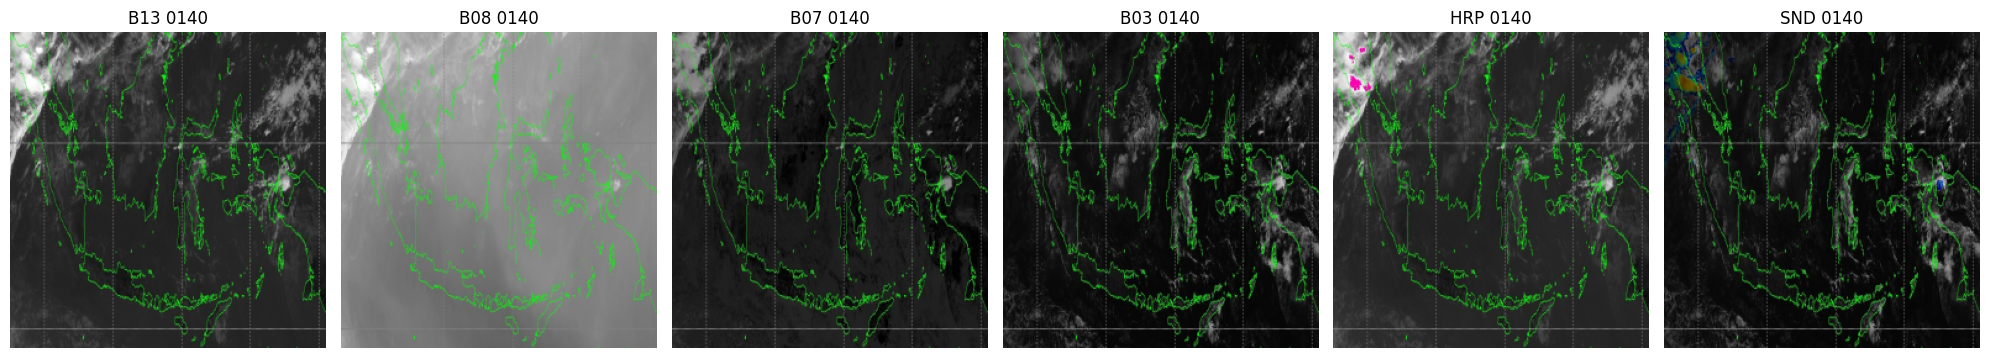

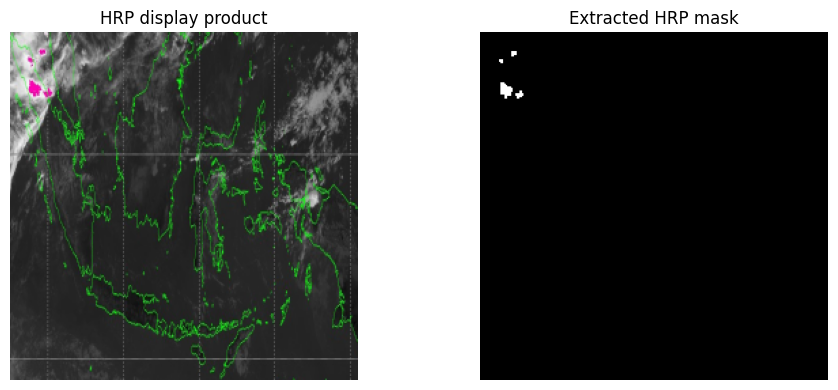

Sample positive pixel ratio: 0.00177001953125


In [5]:

# ============================================================
# 4. PREPROCESSING: CROP INDONESIA, INPUT CHANNEL, DAN MASK HRP
# ============================================================

def read_rgb(path):
    img_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img_bgr is None:
        raise FileNotFoundError(f"Tidak bisa membaca gambar: {path}")
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


def lonlat_to_pixel(lon, lat, width, height, domain=DOMAIN_BBOX):
    x = (lon - domain["lon_min"]) / (domain["lon_max"] - domain["lon_min"]) * width
    y = (domain["lat_max"] - lat) / (domain["lat_max"] - domain["lat_min"]) * height
    return int(round(x)), int(round(y))


def crop_bbox(img_rgb, bbox=INDONESIA_BBOX, domain=DOMAIN_BBOX):
    h, w = img_rgb.shape[:2]
    x1, y1 = lonlat_to_pixel(bbox["lon_min"], bbox["lat_max"], w, h, domain)
    x2, y2 = lonlat_to_pixel(bbox["lon_max"], bbox["lat_min"], w, h, domain)

    x1, x2 = sorted([max(0, x1), min(w, x2)])
    y1, y2 = sorted([max(0, y1), min(h, y2)])

    if x2 <= x1 or y2 <= y1:
        raise ValueError("BBOX crop tidak valid.")

    return img_rgb[y1:y2, x1:x2]


def resize_rgb(img_rgb, size=IMG_SIZE, interpolation=cv2.INTER_AREA):
    return cv2.resize(img_rgb, size, interpolation=interpolation)


def product_to_input_channel(path, product):
    rgb = read_rgb(path)
    cropped = crop_bbox(rgb)
    resized = resize_rgb(cropped, IMG_SIZE)

    # Gray conversion untuk display-product JPG.
    gray = cv2.cvtColor(resized, cv2.COLOR_RGB2GRAY).astype("float32") / 255.0

    # Normalisasi ringan per produk agar rentang channel stabil.
    p2, p98 = np.percentile(gray, [2, 98])
    if p98 > p2:
        gray = np.clip((gray - p2) / (p98 - p2), 0.0, 1.0)

    return gray[..., None]


def extract_hrp_magenta_mask_from_rgb(rgb):
    """Mask HRP berdasarkan magenta.

    Kombinasi RGB + HSV dibuat lebih stabil dibanding threshold RGB saja.
    """
    r = rgb[..., 0].astype(np.int16)
    g = rgb[..., 1].astype(np.int16)
    b = rgb[..., 2].astype(np.int16)

    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    h = hsv[..., 0]
    s = hsv[..., 1]
    v = hsv[..., 2]

    # Magenta pada OpenCV HSV umumnya dekat H 140-170.
    magenta_rgb = (r >= 145) & (b >= 110) & (g <= 140) & ((r - g) >= 45) & ((b - g) >= 20)
    magenta_hsv = (s >= 50) & (v >= 80) & ((h >= 125) | (h <= 5))
    mask = magenta_rgb & magenta_hsv

    mask = mask.astype(np.uint8)

    # Bersihkan noise kecil. Jangan terlalu agresif agar area kecil tidak hilang.
    kernel_open = np.ones((2, 2), np.uint8)
    kernel_close = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close, iterations=1)

    return mask.astype("float32")


def target_to_mask(path, product=TARGET_PRODUCT):
    rgb = read_rgb(path)
    cropped = crop_bbox(rgb)
    resized = resize_rgb(cropped, IMG_SIZE)

    if product.lower() != "hrp":
        raise ValueError("Notebook V2 dirancang untuk TARGET_PRODUCT='hrp'.")

    mask = extract_hrp_magenta_mask_from_rgb(resized)
    return mask[..., None]


# Preview data.
sample_idx = min(10, len(valid_manifest) - 1)
sample = valid_manifest.iloc[sample_idx]

plt.figure(figsize=(20, 4))
for i, product in enumerate(DOWNLOAD_PRODUCTS):
    rgb = resize_rgb(crop_bbox(read_rgb(sample[product])), IMG_SIZE)
    plt.subplot(1, len(DOWNLOAD_PRODUCTS), i + 1)
    plt.imshow(rgb)
    plt.title(f"{product.upper()} {sample['time_code']}")
    plt.axis("off")
plt.tight_layout()
plt.show()

hrp_rgb = resize_rgb(crop_bbox(read_rgb(sample[TARGET_PRODUCT])), IMG_SIZE)
hrp_mask = target_to_mask(sample[TARGET_PRODUCT])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(hrp_rgb)
plt.title("HRP display product")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(hrp_mask[..., 0], cmap="gray")
plt.title("Extracted HRP mask")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Sample positive pixel ratio:", float(hrp_mask.mean()))


In [6]:

# ============================================================
# 5. MEMBANGUN FULL SEQUENCE DATASET
# ============================================================

def build_sequences_from_manifest(df, seq_len=SEQ_LEN, input_products=INPUT_PRODUCTS, target_product=TARGET_PRODUCT):
    df = df[df["is_complete_and_valid"]].sort_values("time_code").reset_index(drop=True)

    if len(df) < seq_len:
        raise RuntimeError("Timestamp valid lebih sedikit dari SEQ_LEN.")

    X, y, meta_rows = [], [], []

    for end_idx in tqdm(range(seq_len - 1, len(df)), desc="Building full sequences"):
        seq_df = df.iloc[end_idx - seq_len + 1:end_idx + 1]
        target_row = df.iloc[end_idx]

        frames = []
        for _, row in seq_df.iterrows():
            channels = []
            for product in input_products:
                channels.append(product_to_input_channel(row[product], product))
            frames.append(np.concatenate(channels, axis=-1))

        X.append(np.stack(frames, axis=0))
        y.append(target_to_mask(target_row[target_product], product=target_product))
        meta_rows.append({
            "sequence_time_codes": ",".join(seq_df["time_code"].tolist()),
            "target_time_code": target_row["time_code"],
            "target_path": target_row[target_product],
        })

    X = np.asarray(X, dtype="float32")
    y = np.asarray(y, dtype="float32")
    meta = pd.DataFrame(meta_rows)

    return X, y, meta


X, y, meta = build_sequences_from_manifest(valid_manifest)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Overall positive pixel ratio:", float(y.mean()))

meta_path = OUTPUT_DIR / "sequence_metadata.csv"
meta.to_csv(meta_path, index=False)
print("Sequence metadata saved:", meta_path)

display(meta.head())


Building full sequences:   0%|          | 0/139 [00:00<?, ?it/s]

X shape: (139, 4, 256, 256, 4)
y shape: (139, 256, 256, 1)
Overall positive pixel ratio: 0.0029004872776567936
Sequence metadata saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260812_0345UTC\sequence_metadata.csv


,sequence_time_codes,target_time_code,target_path
0,"0000,0010,0020,0030",0030,dataset_himawari_r2w\raw\jma_snapshot_20260812...
1,"0010,0020,0030,0040",0040,dataset_himawari_r2w\raw\jma_snapshot_20260812...
2,"0020,0030,0040,0050",0050,dataset_himawari_r2w\raw\jma_snapshot_20260812...
3,"0030,0040,0050,0100",0100,dataset_himawari_r2w\raw\jma_snapshot_20260812...
4,"0040,0050,0100,0110",0110,dataset_himawari_r2w\raw\jma_snapshot_20260812...


In [7]:

# ============================================================
# 6. TEMPORAL SPLIT
# ============================================================

def temporal_split(X, y, meta, train_ratio=0.70, val_ratio=0.15):
    n = len(X)
    train_end = int(n * train_ratio)
    val_end = int(n * (train_ratio + val_ratio))

    X_train, y_train = X[:train_end], y[:train_end]
    X_val, y_val = X[train_end:val_end], y[train_end:val_end]
    X_test, y_test = X[val_end:], y[val_end:]

    meta_train = meta.iloc[:train_end].reset_index(drop=True)
    meta_val = meta.iloc[train_end:val_end].reset_index(drop=True)
    meta_test = meta.iloc[val_end:].reset_index(drop=True)

    if min(len(X_train), len(X_val), len(X_test)) <= 0:
        raise RuntimeError("Split menghasilkan data kosong.")

    return (X_train, y_train, meta_train), (X_val, y_val, meta_val), (X_test, y_test, meta_test)


(train_data, val_data, test_data) = temporal_split(X, y, meta)
X_train, y_train, meta_train = train_data
X_val, y_val, meta_val = val_data
X_test, y_test, meta_test = test_data

split_summary = pd.DataFrame([
    {"split": "train", "n": len(X_train), "positive_pixel_ratio": float(y_train.mean())},
    {"split": "validation", "n": len(X_val), "positive_pixel_ratio": float(y_val.mean())},
    {"split": "test", "n": len(X_test), "positive_pixel_ratio": float(y_test.mean())},
])
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)


,split,n,positive_pixel_ratio
0,train,97,0.002536
1,validation,21,0.003214
2,test,21,0.004272


In [8]:

# ============================================================
# 7. PATCH-BALANCED SAMPLING
# ============================================================

def clamp_int(v, low, high):
    return int(max(low, min(high, v)))


def crop_patch_x_y(X_img, y_img, top, left, patch_size=PATCH_SIZE):
    x_patch = X_img[:, top:top+patch_size, left:left+patch_size, :]
    y_patch = y_img[top:top+patch_size, left:left+patch_size, :]
    return x_patch, y_patch


def sample_positive_patch(X_arr, y_arr, patch_size=PATCH_SIZE, min_positive_pixels=MIN_POSITIVE_PIXELS, max_trials=100):
    n, t, h, w, c = X_arr.shape
    pos_img_indices = np.where(y_arr.reshape(n, -1).sum(axis=1) >= min_positive_pixels)[0]
    if len(pos_img_indices) == 0:
        raise RuntimeError("Tidak ada citra dengan piksel HRP positif cukup untuk positive patch.")

    for _ in range(max_trials):
        idx = int(np.random.choice(pos_img_indices))
        ys, xs = np.where(y_arr[idx, ..., 0] > 0.5)
        if len(xs) == 0:
            continue

        k = np.random.randint(0, len(xs))
        cy, cx = int(ys[k]), int(xs[k])

        top = clamp_int(cy - patch_size // 2 + np.random.randint(-patch_size//4, patch_size//4 + 1), 0, h - patch_size)
        left = clamp_int(cx - patch_size // 2 + np.random.randint(-patch_size//4, patch_size//4 + 1), 0, w - patch_size)

        xp, yp = crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)
        if yp.sum() >= min_positive_pixels:
            return xp, yp

    # Fallback.
    idx = int(np.random.choice(pos_img_indices))
    ys, xs = np.where(y_arr[idx, ..., 0] > 0.5)
    k = np.random.randint(0, len(xs))
    cy, cx = int(ys[k]), int(xs[k])
    top = clamp_int(cy - patch_size // 2, 0, h - patch_size)
    left = clamp_int(cx - patch_size // 2, 0, w - patch_size)
    return crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)


def sample_negative_patch(X_arr, y_arr, patch_size=PATCH_SIZE, max_positive_ratio=NEGATIVE_MAX_POSITIVE_RATIO, max_trials=200):
    n, t, h, w, c = X_arr.shape

    for _ in range(max_trials):
        idx = np.random.randint(0, n)
        top = np.random.randint(0, h - patch_size + 1)
        left = np.random.randint(0, w - patch_size + 1)
        xp, yp = crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)
        if float(yp.mean()) <= max_positive_ratio:
            return xp, yp

    # Fallback: cari patch dengan rasio positif terendah dari beberapa kandidat.
    best = None
    best_ratio = 1.0
    for _ in range(50):
        idx = np.random.randint(0, n)
        top = np.random.randint(0, h - patch_size + 1)
        left = np.random.randint(0, w - patch_size + 1)
        xp, yp = crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)
        ratio = float(yp.mean())
        if ratio < best_ratio:
            best_ratio = ratio
            best = (xp, yp)

    return best


def make_balanced_patches(X_arr, y_arr, n_patches, positive_fraction=POSITIVE_PATCH_FRACTION, patch_size=PATCH_SIZE):
    Xp, yp = [], []
    n_pos = int(round(n_patches * positive_fraction))
    n_neg = n_patches - n_pos

    for _ in tqdm(range(n_pos), desc="Positive patches"):
        x_patch, y_patch = sample_positive_patch(X_arr, y_arr, patch_size=patch_size)
        Xp.append(x_patch)
        yp.append(y_patch)

    for _ in tqdm(range(n_neg), desc="Negative patches"):
        x_patch, y_patch = sample_negative_patch(X_arr, y_arr, patch_size=patch_size)
        Xp.append(x_patch)
        yp.append(y_patch)

    Xp = np.asarray(Xp, dtype="float32")
    yp = np.asarray(yp, dtype="float32")

    order = np.random.permutation(len(Xp))
    return Xp[order], yp[order]


X_train_patch, y_train_patch = make_balanced_patches(X_train, y_train, N_TRAIN_PATCHES)
X_val_patch, y_val_patch = make_balanced_patches(X_val, y_val, N_VAL_PATCHES)

print("Train patch:", X_train_patch.shape, y_train_patch.shape, "positive ratio:", float(y_train_patch.mean()))
print("Val patch  :", X_val_patch.shape, y_val_patch.shape, "positive ratio:", float(y_val_patch.mean()))

patch_summary = pd.DataFrame([
    {"split": "train_patch", "n": len(X_train_patch), "positive_pixel_ratio": float(y_train_patch.mean())},
    {"split": "val_patch", "n": len(X_val_patch), "positive_pixel_ratio": float(y_val_patch.mean())},
])
display(patch_summary)
patch_summary.to_csv(OUTPUT_DIR / "patch_summary.csv", index=False)


Positive patches:   0%|          | 0/1170 [00:00<?, ?it/s]

Negative patches:   0%|          | 0/630 [00:00<?, ?it/s]

Positive patches:   0%|          | 0/292 [00:00<?, ?it/s]

Negative patches:   0%|          | 0/158 [00:00<?, ?it/s]

Train patch: (1800, 4, 128, 128, 4) (1800, 128, 128, 1) positive ratio: 0.008917846716940403
Val patch  : (450, 4, 128, 128, 4) (450, 128, 128, 1) positive ratio: 0.008307020179927349


,split,n,positive_pixel_ratio
0,train_patch,1800,0.008918
1,val_patch,450,0.008307


In [9]:
# ============================================================
# 7B. SAVE TAAC CHECKPOINTS - JALANKAN SETELAH TEMPORAL SPLIT & PATCH
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

BASE_DIR = Path(r"D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program")
CHECKPOINT_DIR = BASE_DIR / "taac_checkpoints_v3"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

def taac_save_array_checkpoints():
    """
    Menyimpan array utama agar eksperimen TAAC bisa dijalankan ulang
    tanpa mengulang preprocessing dari awal.
    """
    required = ["X_train", "y_train", "X_val", "y_val", "X_test", "y_test"]
    missing = [v for v in required if v not in globals()]

    if missing:
        raise RuntimeError(
            "Belum bisa simpan checkpoint. Variabel belum ada: "
            + ", ".join(missing)
            + ". Jalankan dulu cell 6 TEMPORAL SPLIT."
        )

    for name in required:
        arr = globals()[name]
        np.save(CHECKPOINT_DIR / f"{name}.npy", arr)
        print(f"Saved {name}.npy | shape={arr.shape} | positive_ratio={float(np.mean(arr)):.6f}")

    optional_arrays = ["X_train_patch", "y_train_patch", "X_val_patch", "y_val_patch"]

    for name in optional_arrays:
        if name in globals():
            arr = globals()[name]
            np.save(CHECKPOINT_DIR / f"{name}.npy", arr)
            print(f"Saved {name}.npy | shape={arr.shape} | positive_ratio={float(np.mean(arr)):.6f}")
        else:
            print(f"Skip {name}: belum ada di memory.")

    optional_meta = ["meta_train", "meta_val", "meta_test"]

    for name in optional_meta:
        if name in globals() and isinstance(globals()[name], pd.DataFrame):
            path = CHECKPOINT_DIR / f"{name}.csv"
            globals()[name].to_csv(path, index=False)
            print(f"Saved {name}.csv | rows={len(globals()[name])}")

    print("=" * 80)
    print("CHECKPOINT SELESAI.")
    print("Folder:", CHECKPOINT_DIR)
    print("Isi folder:")
    for p in sorted(CHECKPOINT_DIR.glob("*")):
        print("-", p.name)
    print("=" * 80)

    return CHECKPOINT_DIR

def taac_load_array_checkpoints(required_patch=False):
    """
    Memuat kembali checkpoint jika kernel restart.
    """
    required = ["X_train", "y_train", "X_val", "y_val", "X_test", "y_test"]
    missing_files = []

    for name in required:
        path = CHECKPOINT_DIR / f"{name}.npy"
        if not path.exists():
            missing_files.append(str(path))

    if missing_files:
        raise FileNotFoundError(
            "Checkpoint belum lengkap. File hilang: " + "; ".join(missing_files)
        )

    for name in required:
        globals()[name] = np.load(CHECKPOINT_DIR / f"{name}.npy")
        print(f"Loaded {name}.npy | shape={globals()[name].shape} | positive_ratio={float(np.mean(globals()[name])):.6f}")

    for name in ["X_train_patch", "y_train_patch", "X_val_patch", "y_val_patch"]:
        path = CHECKPOINT_DIR / f"{name}.npy"
        if path.exists():
            globals()[name] = np.load(path)
            print(f"Loaded {name}.npy | shape={globals()[name].shape} | positive_ratio={float(np.mean(globals()[name])):.6f}")
        elif required_patch:
            raise FileNotFoundError(f"Patch checkpoint tidak ditemukan: {path}")

    for name in ["meta_train", "meta_val", "meta_test"]:
        path = CHECKPOINT_DIR / f"{name}.csv"
        if path.exists():
            globals()[name] = pd.read_csv(path)
            print(f"Loaded {name}.csv | rows={len(globals()[name])}")

    return True

# Langsung simpan checkpoint ketika cell ini dijalankan.
taac_save_array_checkpoints()


Saved X_train.npy | shape=(97, 4, 256, 256, 4) | positive_ratio=0.238596
Saved y_train.npy | shape=(97, 256, 256, 1) | positive_ratio=0.002536
Saved X_val.npy | shape=(21, 4, 256, 256, 4) | positive_ratio=0.211482
Saved y_val.npy | shape=(21, 256, 256, 1) | positive_ratio=0.003214
Saved X_test.npy | shape=(21, 4, 256, 256, 4) | positive_ratio=0.208283
Saved y_test.npy | shape=(21, 256, 256, 1) | positive_ratio=0.004272
Saved X_train_patch.npy | shape=(1800, 4, 128, 128, 4) | positive_ratio=0.299173
Saved y_train_patch.npy | shape=(1800, 128, 128, 1) | positive_ratio=0.008918
Saved X_val_patch.npy | shape=(450, 4, 128, 128, 4) | positive_ratio=0.269732
Saved y_val_patch.npy | shape=(450, 128, 128, 1) | positive_ratio=0.008307
Saved meta_train.csv | rows=97
Saved meta_val.csv | rows=21
Saved meta_test.csv | rows=21
CHECKPOINT SELESAI.
Folder: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\taac_checkpoints_v3
Isi folder:
- meta_test.csv
- meta_train.csv
- meta_val.csv
- X_test.npy


WindowsPath('D:/RISETKOLABORASI/Artikel Siap Kirim/QUANTUM/Program/taac_checkpoints_v3')

In [10]:

# ============================================================
# 8. TF.DATA PIPELINE
# ============================================================

def augment_sequence_and_mask(x, y):
    # Flip horizontal.
    if tf.random.uniform(()) > 0.5:
        x = tf.reverse(x, axis=[2])
        y = tf.reverse(y, axis=[1])

    # Flip vertical.
    if tf.random.uniform(()) > 0.5:
        x = tf.reverse(x, axis=[1])
        y = tf.reverse(y, axis=[0])

    # Brightness dan contrast kecil pada input.
    delta = tf.random.uniform((), minval=-0.03, maxval=0.03)
    x = tf.clip_by_value(x + delta, 0.0, 1.0)

    contrast = tf.random.uniform((), minval=0.95, maxval=1.05)
    x = tf.clip_by_value((x - 0.5) * contrast + 0.5, 0.0, 1.0)

    return x, y


def make_dataset(X_arr, y_arr, batch_size=BATCH_SIZE, shuffle=False, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((X_arr, y_arr))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(X_arr), 2048), seed=SEED, reshuffle_each_iteration=True)
    if augment:
        ds = ds.map(augment_sequence_and_mask, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


train_patch_ds = make_dataset(X_train_patch, y_train_patch, shuffle=True, augment=True)
val_patch_ds = make_dataset(X_val_patch, y_val_patch, shuffle=False, augment=False)

full_val_ds = make_dataset(X_val, y_val, batch_size=max(1, min(BATCH_SIZE, len(X_val))), shuffle=False, augment=False)
full_test_ds = make_dataset(X_test, y_test, batch_size=max(1, min(BATCH_SIZE, len(X_test))), shuffle=False, augment=False)

print("Dataset pipeline ready.")


Dataset pipeline ready.


In [11]:

# ============================================================
# 9. LOSS DAN METRICS V2
# ============================================================

SMOOTH = 1e-6

def compute_patch_pos_weight(y_patch, min_weight=2.0, max_weight=8.0):
    pos = float(y_patch.mean())
    if pos <= 0:
        return max_weight
    raw = math.sqrt((1.0 - pos) / pos)
    return float(np.clip(raw, min_weight, max_weight))


LOSS_POS_WEIGHT = compute_patch_pos_weight(y_train_patch)
print("LOSS_POS_WEIGHT:", LOSS_POS_WEIGHT)


def dice_coef(y_true, y_pred):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true_f * y_pred_f)
    denom = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    return (2.0 * inter + SMOOTH) / (denom + SMOOTH)


def iou_coef(y_true, y_pred):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - inter
    return (inter + SMOOTH) / (union + SMOOTH)


def weighted_bce_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.clip_by_value(tf.cast(y_pred, tf.float32), 1e-6, 1.0 - 1e-6)

    bce = keras.backend.binary_crossentropy(y_true, y_pred)
    weights = y_true * LOSS_POS_WEIGHT + (1.0 - y_true)
    return tf.reduce_mean(bce * weights)


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


def false_positive_penalty(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    return tf.reduce_mean((1.0 - y_true) * y_pred)


def combined_hrp_loss(y_true, y_pred):
    # FP penalty dimasukkan untuk mencegah model kembali ke solusi all-positive.
    return 0.60 * weighted_bce_loss(y_true, y_pred) + 0.35 * dice_loss(y_true, y_pred) + 0.05 * false_positive_penalty(y_true, y_pred)


def precision_at_05(y_true, y_pred):
    y_pred_bin = tf.cast(y_pred >= 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    fp = tf.reduce_sum((1.0 - y_true) * y_pred_bin)
    return (tp + SMOOTH) / (tp + fp + SMOOTH)


def recall_at_05(y_true, y_pred):
    y_pred_bin = tf.cast(y_pred >= 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    fn = tf.reduce_sum(y_true * (1.0 - y_pred_bin))
    return (tp + SMOOTH) / (tp + fn + SMOOTH)


CUSTOM_OBJECTS = {
    "dice_coef": dice_coef,
    "iou_coef": iou_coef,
    "weighted_bce_loss": weighted_bce_loss,
    "dice_loss": dice_loss,
    "false_positive_penalty": false_positive_penalty,
    "combined_hrp_loss": combined_hrp_loss,
    "precision_at_05": precision_at_05,
    "recall_at_05": recall_at_05,
}


LOSS_POS_WEIGHT: 8.0


In [12]:

# ============================================================
# 10. MODEL DINAMIS: ST-HRPNet v1 Patch-Balanced
# ============================================================

def td_conv_block(x, filters, name, dropout=0.0):
    x = layers.TimeDistributed(
        layers.SeparableConv2D(filters, 3, padding="same", use_bias=False),
        name=f"{name}_sepconv1"
    )(x)
    x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_bn1")(x)
    x = layers.TimeDistributed(layers.Activation("relu"), name=f"{name}_relu1")(x)

    x = layers.TimeDistributed(
        layers.SeparableConv2D(filters, 3, padding="same", use_bias=False),
        name=f"{name}_sepconv2"
    )(x)
    x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_bn2")(x)
    x = layers.TimeDistributed(layers.Activation("relu"), name=f"{name}_relu2")(x)

    if dropout > 0:
        x = layers.TimeDistributed(layers.SpatialDropout2D(dropout), name=f"{name}_drop")(x)

    return x


def conv_block_2d(x, filters, name, dropout=0.0):
    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_sepconv1")(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_sepconv2")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)

    if dropout > 0:
        x = layers.SpatialDropout2D(dropout, name=f"{name}_drop")(x)

    return x


def last_time_step(x):
    return x[:, -1, ...]


def build_st_hrpnet_v1_patchbalanced(seq_len=SEQ_LEN, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    inputs = keras.Input(shape=(seq_len, None, None, n_channels), name="himawari_sequence_dynamic")

    x1 = td_conv_block(inputs, base, "enc1", dropout=0.03)
    p1 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool1")(x1)

    x2 = td_conv_block(p1, base * 2, "enc2", dropout=0.05)
    p2 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool2")(x2)

    x3 = td_conv_block(p2, base * 4, "enc3", dropout=0.08)
    p3 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool3")(x3)

    b = layers.ConvLSTM2D(
        base * 8,
        3,
        padding="same",
        return_sequences=False,
        dropout=0.15,
        recurrent_dropout=0.0,
        name="conv_lstm_bottleneck"
    )(p3)
    b = layers.BatchNormalization(name="bottleneck_bn")(b)
    b = layers.Activation("relu", name="bottleneck_relu")(b)

    s3 = layers.Lambda(last_time_step, name="skip3_last")(x3)
    s2 = layers.Lambda(last_time_step, name="skip2_last")(x2)
    s1 = layers.Lambda(last_time_step, name="skip1_last")(x1)

    u3 = layers.UpSampling2D((2, 2), name="up3")(b)
    u3 = layers.Concatenate(name="cat3")([u3, s3])
    d3 = conv_block_2d(u3, base * 4, "dec3", dropout=0.05)

    u2 = layers.UpSampling2D((2, 2), name="up2")(d3)
    u2 = layers.Concatenate(name="cat2")([u2, s2])
    d2 = conv_block_2d(u2, base * 2, "dec2", dropout=0.03)

    u1 = layers.UpSampling2D((2, 2), name="up1")(d2)
    u1 = layers.Concatenate(name="cat1")([u1, s1])
    d1 = conv_block_2d(u1, base, "dec1", dropout=0.02)

    outputs = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(d1)

    return keras.Model(inputs, outputs, name="ST_HRPNet_v1_PatchBalanced")


def compile_model(model, lr=LEARNING_RATE):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=combined_hrp_loss,
        metrics=[dice_coef, iou_coef, precision_at_05, recall_at_05],
    )
    return model


st_model = compile_model(build_st_hrpnet_v1_patchbalanced())
st_model.summary()


Model: "ST_HRPNet_v1_PatchBalanced"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 himawari_sequence_dynamic   [(None, 4, None, None, 4)]   0         []                            
 (InputLayer)                                                                                     
                                                                                                  
 enc1_sepconv1 (TimeDistrib  (None, 4, None, None, 24)    132       ['himawari_sequence_dynamic[0]
 uted)                                                              [0]']                         
                                                                                                  
 enc1_bn1 (TimeDistributed)  (None, 4, None, None, 24)    96        ['enc1_sepconv1[0][0]']       
                                                                         

In [29]:

# ============================================================
# 11. BASELINE MODELS DINAMIS
# ============================================================

def build_unet2d_baseline(n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    inp = keras.Input(shape=(None, None, n_channels), name="last_frame_dynamic")

    c1 = conv_block_2d(inp, base, "u_enc1", dropout=0.03)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block_2d(p1, base * 2, "u_enc2", dropout=0.05)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block_2d(p2, base * 4, "u_enc3", dropout=0.08)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    b = conv_block_2d(p3, base * 8, "u_bottleneck", dropout=0.10)

    u3 = layers.UpSampling2D((2, 2))(b)
    u3 = layers.Concatenate()([u3, c3])
    d3 = conv_block_2d(u3, base * 4, "u_dec3", dropout=0.05)

    u2 = layers.UpSampling2D((2, 2))(d3)
    u2 = layers.Concatenate()([u2, c2])
    d2 = conv_block_2d(u2, base * 2, "u_dec2", dropout=0.03)

    u1 = layers.UpSampling2D((2, 2))(d2)
    u1 = layers.Concatenate()([u1, c1])
    d1 = conv_block_2d(u1, base, "u_dec1", dropout=0.02)

    out = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(d1)
    return keras.Model(inp, out, name="UNet2D_LastFrame_Baseline_V2")


def build_convlstm_simple_baseline(seq_len=SEQ_LEN, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    inp = keras.Input(shape=(seq_len, None, None, n_channels), name="sequence_dynamic")
    x = layers.ConvLSTM2D(base, 3, padding="same", return_sequences=True, name="clstm1")(inp)
    x = layers.BatchNormalization()(x)
    x = layers.ConvLSTM2D(base * 2, 3, padding="same", return_sequences=False, name="clstm2")(x)
    x = layers.BatchNormalization()(x)
    x = conv_block_2d(x, base * 2, "clstm_refine", dropout=0.05)
    out = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(x)
    return keras.Model(inp, out, name="ConvLSTM_Simple_Baseline_V2")


def build_3dcnn_baseline(seq_len=SEQ_LEN, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    inp = keras.Input(shape=(seq_len, None, None, n_channels), name="sequence_dynamic")
    x = layers.Conv3D(base, (3, 3, 3), padding="same", activation="relu", name="conv3d_1")(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Conv3D(base, (3, 3, 3), padding="same", activation="relu", name="conv3d_2")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Lambda(lambda z: tf.reduce_mean(z, axis=1), name="temporal_average")(x)
    x = conv_block_2d(x, base * 2, "cnn3d_refine1", dropout=0.05)
    x = conv_block_2d(x, base, "cnn3d_refine2", dropout=0.03)
    out = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(x)
    return keras.Model(inp, out, name="CNN3D_Baseline_V2")

print("Baseline builders ready.")


Baseline builders ready.


In [14]:

# ============================================================
# 12. TRAINING FUNCTION AMAN KERAS 2.13
# ============================================================

def train_model(model, train_data, val_data, name, epochs):
    model_dir = OUTPUT_DIR / name
    model_dir.mkdir(parents=True, exist_ok=True)

    ckpt_path = model_dir / f"{name}_best.weights.h5"

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(ckpt_path),
            monitor="val_iou_coef",
            mode="max",
            save_best_only=True,
            save_weights_only=True,
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_iou_coef",
            mode="max",
            patience=14,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=1,
        ),
        keras.callbacks.CSVLogger(str(model_dir / f"{name}_training_log.csv")),
    ]

    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=epochs,
        callbacks=callbacks,
        verbose=1,
    )

    hist_df = pd.DataFrame(history.history)
    hist_df.to_csv(model_dir / f"{name}_history.csv", index=False)

    # Pastikan bobot terbaik tersedia jika checkpoint berhasil tersimpan.
    if ckpt_path.exists():
        model.load_weights(str(ckpt_path))

    return model, hist_df, model_dir


st_model, st_history, st_model_dir = train_model(
    st_model,
    train_patch_ds,
    val_patch_ds,
    name="ST_HRPNet_v1_PatchBalanced",
    epochs=EPOCHS_MAIN,
)

print("Training ST-HRPNet v1 Patch-Balanced selesai.")


Epoch 1/70
225/225 [==============================] - ETA: 0s - loss: 0.4753 - dice_coef: 0.1748 - iou_coef: 0.0979 - precision_at_05: 0.2917 - recall_at_05: 0.8736
Epoch 1: val_iou_coef improved from -inf to 0.02422, saving model to outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced\ST_HRPNet_v1_PatchBalanced_best.weights.h5
225/225 [==============================] - 286s 1s/step - loss: 0.4753 - dice_coef: 0.1748 - iou_coef: 0.0979 - precision_at_05: 0.2917 - recall_at_05: 0.8736 - val_loss: 0.6510 - val_dice_coef: 0.0472 - val_iou_coef: 0.0242 - val_precision_at_05: 1.0000 - val_recall_at_05: 3.2886e-10 - lr: 7.0000e-04
Epoch 2/70
225/225 [==============================] - ETA: 0s - loss: 0.2947 - dice_coef: 0.3881 - iou_coef: 0.2442 - precision_at_05: 0.4225 - recall_at_05: 0.8643
Epoch 2: val_iou_coef did not improve from 0.02422
225/225 [==============================] - 265s 1s/step - loss: 0.2947 - dice_coef: 0.3881

In [15]:

# ============================================================
# 13. TRAINING BASELINE COMPARISON
# ============================================================

baseline_models = {}

if RUN_BASELINES:
    # U-Net 2D memakai frame terakhir dari patch.
    X_train_patch_last = X_train_patch[:, -1, ...]
    X_val_patch_last = X_val_patch[:, -1, ...]

    def make_2d_dataset(X_arr, y_arr, batch_size=BATCH_SIZE, shuffle=False):
        ds = tf.data.Dataset.from_tensor_slices((X_arr, y_arr))
        if shuffle:
            ds = ds.shuffle(buffer_size=min(len(X_arr), 2048), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
        return ds

    train_2d_ds = make_2d_dataset(X_train_patch_last, y_train_patch, shuffle=True)
    val_2d_ds = make_2d_dataset(X_val_patch_last, y_val_patch, shuffle=False)

    unet_model = compile_model(build_unet2d_baseline())
    unet_model, unet_hist, unet_dir = train_model(
        unet_model,
        train_2d_ds,
        val_2d_ds,
        name="UNet2D_LastFrame_Baseline_V2",
        epochs=EPOCHS_BASELINE,
    )
    baseline_models["UNet2D_LastFrame_Baseline_V2"] = {
        "model": unet_model,
        "input_type": "2d_last_frame",
    }

    convlstm_base = compile_model(build_convlstm_simple_baseline())
    convlstm_base, convlstm_hist, convlstm_dir = train_model(
        convlstm_base,
        train_patch_ds,
        val_patch_ds,
        name="ConvLSTM_Simple_Baseline_V2",
        epochs=EPOCHS_BASELINE,
    )
    baseline_models["ConvLSTM_Simple_Baseline_V2"] = {
        "model": convlstm_base,
        "input_type": "sequence",
    }

    cnn3d_base = compile_model(build_3dcnn_baseline())
    cnn3d_base, cnn3d_hist, cnn3d_dir = train_model(
        cnn3d_base,
        train_patch_ds,
        val_patch_ds,
        name="CNN3D_Baseline_V2",
        epochs=EPOCHS_BASELINE,
    )
    baseline_models["CNN3D_Baseline_V2"] = {
        "model": cnn3d_base,
        "input_type": "sequence",
    }
else:
    print("RUN_BASELINES=False, baseline dilewati.")


Epoch 1/40
225/225 [==============================] - ETA: 0s - loss: 0.4149 - dice_coef: 0.2386 - iou_coef: 0.1412 - precision_at_05: 0.3664 - recall_at_05: 0.9088
Epoch 1: val_iou_coef improved from -inf to 0.02157, saving model to outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\UNet2D_LastFrame_Baseline_V2\UNet2D_LastFrame_Baseline_V2_best.weights.h5
225/225 [==============================] - 111s 464ms/step - loss: 0.4149 - dice_coef: 0.2386 - iou_coef: 0.1412 - precision_at_05: 0.3664 - recall_at_05: 0.9088 - val_loss: 0.6712 - val_dice_coef: 0.0422 - val_iou_coef: 0.0216 - val_precision_at_05: 1.0000 - val_recall_at_05: 3.2886e-10 - lr: 7.0000e-04
Epoch 2/40
225/225 [==============================] - ETA: 0s - loss: 0.2057 - dice_coef: 0.5581 - iou_coef: 0.3937 - precision_at_05: 0.5914 - recall_at_05: 0.8989
Epoch 2: val_iou_coef did not improve from 0.02157
225/225 [==============================] - 104s 461ms/step - loss: 0.2057 - dice_co

In [29]:
# ============================================================
# 14. EVALUASI FULL-IMAGE DENGAN CONSTRAINED THRESHOLD — VISIBLE VERSION
# ============================================================

from IPython.display import display

print("Mulai Cell #14: Evaluasi full-image...")

# ------------------------------------------------------------
# A. Validasi variabel wajib
# ------------------------------------------------------------
required_vars = ["X_val", "y_val", "X_test", "y_test", "st_model", "OUTPUT_DIR"]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise RuntimeError(
        f"Variabel berikut belum tersedia: {missing_vars}. "
        "Jalankan cell sebelumnya secara berurutan sampai training selesai."
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if "BATCH_SIZE" not in globals():
    BATCH_SIZE = 4

print("X_val :", X_val.shape, "y_val :", y_val.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)
print("Actual positive ratio val :", float(np.asarray(y_val).mean()))
print("Actual positive ratio test:", float(np.asarray(y_test).mean()))


# ------------------------------------------------------------
# B. Fungsi prediksi full-image
# ------------------------------------------------------------
def predict_full(model, X_arr, input_type="sequence", batch_size=None, verbose=1):
    if batch_size is None:
        batch_size = max(1, min(BATCH_SIZE, len(X_arr)))

    if input_type == "2d_last_frame":
        arr = X_arr[:, -1, ...]
    else:
        arr = X_arr

    print(f"Predicting: input_type={input_type}, arr_shape={arr.shape}, batch_size={batch_size}")
    pred = model.predict(arr, batch_size=batch_size, verbose=verbose)
    pred = np.asarray(pred, dtype=np.float64)
    pred = np.nan_to_num(pred, nan=0.0, posinf=1.0, neginf=0.0)
    pred = np.clip(pred, 0.0, 1.0)
    print("Prediction shape:", pred.shape, "min:", float(pred.min()), "max:", float(pred.max()), "mean:", float(pred.mean()))
    return pred


# ------------------------------------------------------------
# C. Fungsi metrik aman
# ------------------------------------------------------------
def binary_metrics_np(y_true, y_prob, threshold=0.5):
    yt = (np.asarray(y_true).reshape(-1) >= 0.5).astype(np.uint8)

    yp_prob = np.asarray(y_prob).reshape(-1).astype(np.float64)
    yp_prob = np.nan_to_num(yp_prob, nan=0.0, posinf=1.0, neginf=0.0)
    yp_prob = np.clip(yp_prob, 0.0, 1.0)

    if yt.shape[0] != yp_prob.shape[0]:
        raise ValueError(
            f"Jumlah pixel y_true dan y_prob tidak sama: "
            f"{yt.shape[0]} vs {yp_prob.shape[0]}. "
            "Cek output model dan ukuran label."
        )

    yp = (yp_prob >= float(threshold)).astype(np.uint8)

    tp_i = int(np.sum((yt == 1) & (yp == 1)))
    fp_i = int(np.sum((yt == 0) & (yp == 1)))
    fn_i = int(np.sum((yt == 1) & (yp == 0)))
    tn_i = int(np.sum((yt == 0) & (yp == 0)))

    tp = float(tp_i)
    fp = float(fp_i)
    fn = float(fn_i)
    tn = float(tn_i)

    precision = tp / (tp + fp + 1e-7)
    recall = tp / (tp + fn + 1e-7)
    specificity = tn / (tn + fp + 1e-7)
    fpr = fp / (fp + tn + 1e-7)
    dice = 2.0 * tp / (2.0 * tp + fp + fn + 1e-7)
    iou = tp / (tp + fp + fn + 1e-7)
    accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-7)
    balanced_accuracy = 0.5 * (recall + specificity)

    denom_product = (tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)
    denom = math.sqrt(max(denom_product, 0.0)) + 1e-7
    mcc = ((tp * tn) - (fp * fn)) / denom

    return {
        "threshold": float(threshold),
        "iou": float(iou),
        "dice_f1": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "specificity": float(specificity),
        "fpr": float(fpr),
        "accuracy": float(accuracy),
        "balanced_accuracy": float(balanced_accuracy),
        "mcc": float(mcc),
        "actual_positive_ratio": float(yt.mean()),
        "predicted_positive_ratio": float(yp.mean()),
        "tp": tp_i,
        "fp": fp_i,
        "fn": fn_i,
        "tn": tn_i,
    }


def pr_auc_score_np(y_true, y_prob):
    yt = (np.asarray(y_true).reshape(-1) >= 0.5).astype(np.uint8)
    yp = np.asarray(y_prob).reshape(-1).astype(np.float64)
    yp = np.nan_to_num(yp, nan=0.0, posinf=1.0, neginf=0.0)
    yp = np.clip(yp, 0.0, 1.0)

    if len(np.unique(yt)) < 2:
        return np.nan

    precision, recall, _ = precision_recall_curve(yt, yp)
    return float(auc(recall, precision))


# ------------------------------------------------------------
# D. Threshold search yang menampilkan hasil
# ------------------------------------------------------------
def select_threshold_constrained(y_true, y_prob, model_name="model"):
    actual_ratio = float((np.asarray(y_true).reshape(-1) >= 0.5).mean())
    thresholds = np.round(np.arange(0.01, 0.991, 0.01), 2)

    min_pred_ratio = max(actual_ratio * 0.10, 0.0002)
    max_pred_ratio = min(max(actual_ratio * 8.0, 0.08), 0.35)

    print(f"\nThreshold search untuk {model_name}")
    print(f"actual_ratio={actual_ratio:.6f}, min_pred_ratio={min_pred_ratio:.6f}, max_pred_ratio={max_pred_ratio:.6f}")

    rows = []
    for th in thresholds:
        m = binary_metrics_np(y_true, y_prob, threshold=float(th))
        pred_ratio = m["predicted_positive_ratio"]

        ratio_penalty = abs(math.log((pred_ratio + 1e-8) / (actual_ratio + 1e-8)))
        m["ratio_penalty"] = float(ratio_penalty)
        m["is_ratio_valid"] = bool((pred_ratio >= min_pred_ratio) and (pred_ratio <= max_pred_ratio))

        m["selection_score"] = float(
            m["iou"]
            + 0.20 * m["dice_f1"]
            + 0.10 * m["balanced_accuracy"]
            + 0.10 * m["mcc"]
            - 0.025 * ratio_penalty
        )
        rows.append(m)

    df = pd.DataFrame(rows)

    valid = df[df["is_ratio_valid"]].copy()
    if len(valid) > 0:
        best_idx = valid["selection_score"].idxmax()
        print("Threshold dipilih dari kandidat valid ratio.")
    else:
        best_idx = df["selection_score"].idxmax()
        print("PERINGATAN: tidak ada threshold dengan predicted ratio valid. Dipilih dari semua threshold.")

    best_th = float(df.loc[best_idx, "threshold"])

    print("\nTop-10 threshold candidates:")
    display(
        df.sort_values("selection_score", ascending=False)
          .head(10)[[
              "threshold", "iou", "dice_f1", "precision", "recall",
              "specificity", "mcc", "actual_positive_ratio",
              "predicted_positive_ratio", "is_ratio_valid", "selection_score"
          ]]
    )

    print(f"Best threshold {model_name}: {best_th:.2f}")
    return best_th, df


# ------------------------------------------------------------
# E. Inference time
# ------------------------------------------------------------
def measure_inference_time(model, input_type="sequence", n_repeat=3):
    n_sample = min(len(X_test), max(1, min(BATCH_SIZE, 4)))

    if input_type == "2d_last_frame":
        arr = X_test[:n_sample, -1, ...]
    else:
        arr = X_test[:n_sample]

    _ = model.predict(arr, verbose=0)

    times = []
    for _ in range(n_repeat):
        start = time.time()
        _ = model.predict(arr, verbose=0)
        elapsed = time.time() - start
        times.append(elapsed / len(arr))

    return float(np.mean(times)), float(np.std(times))


# ------------------------------------------------------------
# F. Daftar model yang dievaluasi
# ------------------------------------------------------------
models_to_eval = {
    "ST_HRPNet_v1_PatchBalanced": {
        "model": st_model,
        "input_type": "sequence",
    }
}

if "baseline_models" in globals() and isinstance(baseline_models, dict) and len(baseline_models) > 0:
    for k, v in baseline_models.items():
        if isinstance(v, dict) and "model" in v and "input_type" in v:
            models_to_eval[k] = v
else:
    print("baseline_models tidak tersedia/kosong. Evaluasi hanya ST-HRPNet.")


print("\nModel yang akan dievaluasi:")
for name in models_to_eval:
    print("-", name)


# ------------------------------------------------------------
# G. Evaluasi final
# ------------------------------------------------------------
evaluation_rows = []
threshold_frames = {}

for model_name, obj in models_to_eval.items():
    print("\n" + "=" * 80)
    print("Evaluating:", model_name)
    print("=" * 80)

    model_obj = obj["model"]
    input_type = obj.get("input_type", "sequence")

    try:
        print("\n[1/4] Predict validation set...")
        val_prob = predict_full(model_obj, X_val, input_type=input_type, verbose=1)

        print("\n[2/4] Select constrained threshold...")
        best_th, th_df = select_threshold_constrained(y_val, val_prob, model_name=model_name)
        threshold_frames[model_name] = th_df

        th_path = OUTPUT_DIR / f"{model_name}_threshold_search_constrained_val.csv"
        th_df.to_csv(th_path, index=False)
        print("Threshold search saved:", th_path)

        print("\n[3/4] Predict test set...")
        test_prob = predict_full(model_obj, X_test, input_type=input_type, verbose=1)

        print("\n[4/4] Compute final test metrics...")
        metrics = binary_metrics_np(y_test, test_prob, threshold=best_th)
        metrics["model"] = model_name
        metrics["pr_auc"] = pr_auc_score_np(y_test, test_prob)

        inf_mean, inf_std = measure_inference_time(model_obj, input_type=input_type)
        metrics["inference_sec_per_sample_mean"] = inf_mean
        metrics["inference_sec_per_sample_std"] = inf_std

        evaluation_rows.append(metrics)

        print("Final metrics:")
        display(pd.DataFrame([metrics]))

    except Exception as e:
        print(f"ERROR saat evaluasi {model_name}: {repr(e)}")
        evaluation_rows.append({
            "model": model_name,
            "threshold": np.nan,
            "iou": np.nan,
            "dice_f1": np.nan,
            "precision": np.nan,
            "recall": np.nan,
            "specificity": np.nan,
            "fpr": np.nan,
            "accuracy": np.nan,
            "balanced_accuracy": np.nan,
            "mcc": np.nan,
            "pr_auc": np.nan,
            "actual_positive_ratio": float(np.asarray(y_test).mean()),
            "predicted_positive_ratio": np.nan,
            "inference_sec_per_sample_mean": np.nan,
            "inference_sec_per_sample_std": np.nan,
            "tp": np.nan,
            "fp": np.nan,
            "fn": np.nan,
            "tn": np.nan,
            "error": repr(e),
        })


# ------------------------------------------------------------
# H. Simpan dan tampilkan hasil
# ------------------------------------------------------------
results_df = pd.DataFrame(evaluation_rows)

expected_cols = [
    "model", "threshold", "iou", "dice_f1", "precision", "recall",
    "specificity", "fpr", "accuracy", "balanced_accuracy", "mcc", "pr_auc",
    "actual_positive_ratio", "predicted_positive_ratio",
    "inference_sec_per_sample_mean", "inference_sec_per_sample_std",
    "tp", "fp", "fn", "tn"
]

for col in expected_cols:
    if col not in results_df.columns:
        results_df[col] = np.nan

results_df = results_df[expected_cols + [c for c in results_df.columns if c not in expected_cols]]
results_df = results_df.sort_values(["iou", "mcc", "pr_auc"], ascending=False, na_position="last").reset_index(drop=True)

results_path = OUTPUT_DIR / "paper_ready_model_comparison_results_V2.csv"
results_df.to_csv(results_path, index=False)

print("\n" + "=" * 80)
print("HASIL AKHIR EVALUASI FULL-IMAGE")
print("=" * 80)
display(results_df)

print("Results saved:", results_path)

if len(results_df) > 0 and "iou" in results_df.columns:
    best = results_df.iloc[0]
    print("\nBest model sementara:")
    print("Model     :", best.get("model"))
    print("Threshold :", best.get("threshold"))
    print("IoU       :", best.get("iou"))
    print("Dice/F1   :", best.get("dice_f1"))
    print("Precision :", best.get("precision"))
    print("Recall    :", best.get("recall"))
    print("MCC       :", best.get("mcc"))
    print("PR-AUC    :", best.get("pr_auc"))
    print("Pred Pos  :", best.get("predicted_positive_ratio"))

Mulai Cell #14: Evaluasi full-image...
X_val : (21, 4, 256, 256, 4) y_val : (21, 256, 256, 1)
X_test: (21, 4, 256, 256, 4) y_test: (21, 256, 256, 1)
Actual positive ratio val : 0.0257241390645504
Actual positive ratio test: 0.0252874456346035

Model yang akan dievaluasi:
- ST_HRPNet_v1_PatchBalanced
- UNet2D_LastFrame_Baseline_V2
- ConvLSTM_Simple_Baseline_V2
- CNN3D_Baseline_V2

Evaluating: ST_HRPNet_v1_PatchBalanced

[1/4] Predict validation set...
Predicting: input_type=sequence, arr_shape=(21, 4, 256, 256, 4), batch_size=8
3/3 [==============================] - 2s 500ms/step
Prediction shape: (21, 256, 256, 1) min: 2.8630056547740423e-08 max: 0.9999985098838806 mean: 0.027944007901991454

[2/4] Select constrained threshold...

Threshold search untuk ST_HRPNet_v1_PatchBalanced
actual_ratio=0.025724, min_pred_ratio=0.002572, max_pred_ratio=0.205793
Threshold dipilih dari kandidat valid ratio.

Top-10 threshold candidates:


,threshold,iou,dice_f1,precision,recall,specificity,mcc,actual_positive_ratio,predicted_positive_ratio,is_ratio_valid,selection_score
49,0.50,0.690658,0.817029,0.787455,0.848911,0.993950,0.812617,0.025724,0.027732,True,1.025590
52,0.53,0.690549,0.816952,0.791861,0.843686,0.994145,0.812392,0.025724,0.027408,True,1.025485
50,0.51,0.690547,0.816951,0.788725,0.847273,0.994008,0.812490,0.025724,0.027634,True,1.025461
48,0.49,0.690448,0.816882,0.785899,0.850408,0.993883,0.812518,0.025724,0.027836,True,1.025319
46,0.47,0.690315,0.816788,0.783187,0.853402,0.993762,0.812528,0.025724,0.028030,True,1.025137
47,0.48,0.690306,0.816782,0.784536,0.851792,0.993823,0.812465,0.025724,0.027929,True,1.025133
51,0.52,0.690256,0.816747,0.790336,0.844985,0.994081,0.812221,0.025724,0.027503,True,1.025109
53,0.54,0.690162,0.816682,0.793201,0.841595,0.994207,0.812070,0.025724,0.027294,True,1.025015
45,0.46,0.690047,0.816601,0.781469,0.855041,0.993687,0.812403,0.025724,0.028146,True,1.024795
44,0.45,0.689820,0.816442,0.779792,0.856707,0.993612,0.812309,0.025724,0.028261,True,1.024503


Best threshold ST_HRPNet_v1_PatchBalanced: 0.50
Threshold search saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_threshold_search_constrained_val.csv

[3/4] Predict test set...
Predicting: input_type=sequence, arr_shape=(21, 4, 256, 256, 4), batch_size=8
3/3 [==============================] - 2s 492ms/step
Prediction shape: (21, 256, 256, 1) min: 2.7341927832935653e-08 max: 0.9999971985816956 mean: 0.024514955337039714

[4/4] Compute final test metrics...
Final metrics:


,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,actual_positive_ratio,predicted_positive_ratio,tp,fp,fn,tn,model,pr_auc,inference_sec_per_sample_mean,inference_sec_per_sample_std
0,0.5,0.639926,0.780433,0.796642,0.76487,0.994935,0.005065,0.989117,0.879902,0.775024,0.025287,0.024279,26619,6795,8183,1334659,ST_HRPNet_v1_PatchBalanced,0.865769,0.094218,0.00267



Evaluating: UNet2D_LastFrame_Baseline_V2

[1/4] Predict validation set...
Predicting: input_type=2d_last_frame, arr_shape=(21, 256, 256, 4), batch_size=8
3/3 [==============================] - 1s 147ms/step
Prediction shape: (21, 256, 256, 1) min: 4.935379394055417e-08 max: 0.9999998807907104 mean: 0.02703630028109662

[2/4] Select constrained threshold...

Threshold search untuk UNet2D_LastFrame_Baseline_V2
actual_ratio=0.025724, min_pred_ratio=0.002572, max_pred_ratio=0.205793
Threshold dipilih dari kandidat valid ratio.

Top-10 threshold candidates:


,threshold,iou,dice_f1,precision,recall,specificity,mcc,actual_positive_ratio,predicted_positive_ratio,is_ratio_valid,selection_score
38,0.39,0.687003,0.814466,0.784589,0.846708,0.993862,0.809995,0.025724,0.027761,True,1.021019
37,0.38,0.686975,0.814446,0.783585,0.847838,0.993817,0.810012,0.025724,0.027833,True,1.020978
36,0.37,0.686876,0.814376,0.782469,0.848996,0.993768,0.809981,0.025724,0.027911,True,1.020847
28,0.29,0.686788,0.814315,0.773001,0.860294,0.993330,0.810366,0.025724,0.028629,True,1.020694
35,0.36,0.686635,0.814207,0.781128,0.850210,0.993710,0.809855,0.025724,0.027999,True,1.020539
27,0.28,0.686655,0.814221,0.771718,0.861678,0.993270,0.810337,0.025724,0.028723,True,1.020523
39,0.40,0.686578,0.814167,0.785420,0.845098,0.993904,0.809648,0.025724,0.027679,True,1.020495
31,0.32,0.686589,0.814175,0.776269,0.855973,0.993486,0.810043,0.025724,0.028365,True,1.020458
32,0.33,0.686514,0.814122,0.777595,0.854250,0.993549,0.809921,0.025724,0.028260,True,1.020370
25,0.26,0.686494,0.814108,0.768974,0.864870,0.993139,0.810380,0.025724,0.028932,True,1.020316


... (9 outputs left out)

,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,actual_positive_ratio,predicted_positive_ratio,tp,fp,fn,tn,model,pr_auc,inference_sec_per_sample_mean,inference_sec_per_sample_std
0,0.69,0.596369,0.747157,0.804441,0.697489,0.995601,0.004399,0.988063,0.846545,0.743054,0.025287,0.021925,24274,5901,10528,1335553,CNN3D_Baseline_V2,0.840459,0.060294,0.001089



HASIL AKHIR EVALUASI FULL-IMAGE


,model,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,pr_auc,actual_positive_ratio,predicted_positive_ratio,inference_sec_per_sample_mean,inference_sec_per_sample_std,tp,fp,fn,tn
0,ST_HRPNet_v1_PatchBalanced,0.50,0.639926,0.780433,0.796642,0.764870,0.994935,0.005065,0.989117,0.879902,0.775024,0.865769,0.025287,0.024279,0.094218,0.002670,26619,6795,8183,1334659
1,ConvLSTM_Simple_Baseline_V2,0.66,0.616785,0.762977,0.813148,0.718637,0.995716,0.004284,0.988709,0.857176,0.758733,0.855746,0.025287,0.022348,0.257966,0.002344,25010,5747,9792,1335707
2,UNet2D_LastFrame_Baseline_V2,0.39,0.609877,0.757669,0.799088,0.720332,0.995301,0.004699,0.988348,0.857817,0.752778,0.843583,0.025287,0.022795,0.031186,0.000457,25069,6303,9733,1335151
3,CNN3D_Baseline_V2,0.69,0.596369,0.747157,0.804441,0.697489,0.995601,0.004399,0.988063,0.846545,0.743054,0.840459,0.025287,0.021925,0.060294,0.001089,24274,5901,10528,1335553


Results saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\paper_ready_model_comparison_results_V2.csv

Best model sementara:
Model     : ST_HRPNet_v1_PatchBalanced
Threshold : 0.5
IoU       : 0.6399259561972259
Dice/F1   : 0.7804327430503395
Precision : 0.7966421260525629
Recall    : 0.7648698350647524
MCC       : 0.7750239550496076
PR-AUC    : 0.8657686953555256
Pred Pos  : 0.024278913225446428


,model,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,pr_auc,actual_positive_ratio,predicted_positive_ratio,inference_sec_per_sample_mean,inference_sec_per_sample_std,tp,fp,fn,tn
0,ST_HRPNet_v1_PatchBalanced,0.50,0.639926,0.780433,0.796642,0.764870,0.994935,0.005065,0.989117,0.879902,0.775024,0.865769,0.025287,0.024279,0.094218,0.002670,26619,6795,8183,1334659
1,ConvLSTM_Simple_Baseline_V2,0.66,0.616785,0.762977,0.813148,0.718637,0.995716,0.004284,0.988709,0.857176,0.758733,0.855746,0.025287,0.022348,0.257966,0.002344,25010,5747,9792,1335707
2,UNet2D_LastFrame_Baseline_V2,0.39,0.609877,0.757669,0.799088,0.720332,0.995301,0.004699,0.988348,0.857817,0.752778,0.843583,0.025287,0.022795,0.031186,0.000457,25069,6303,9733,1335151
3,CNN3D_Baseline_V2,0.69,0.596369,0.747157,0.804441,0.697489,0.995601,0.004399,0.988063,0.846545,0.743054,0.840459,0.025287,0.021925,0.060294,0.001089,24274,5901,10528,1335553


Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_000.png


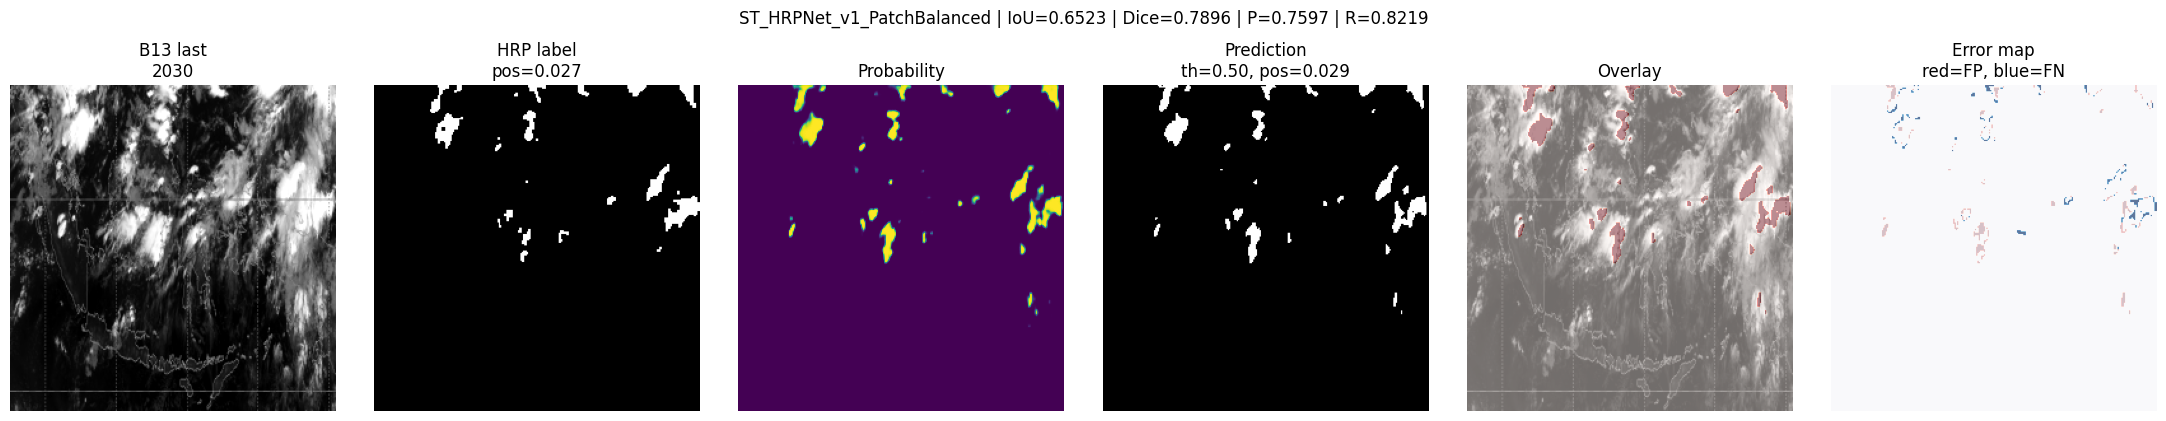

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_001.png


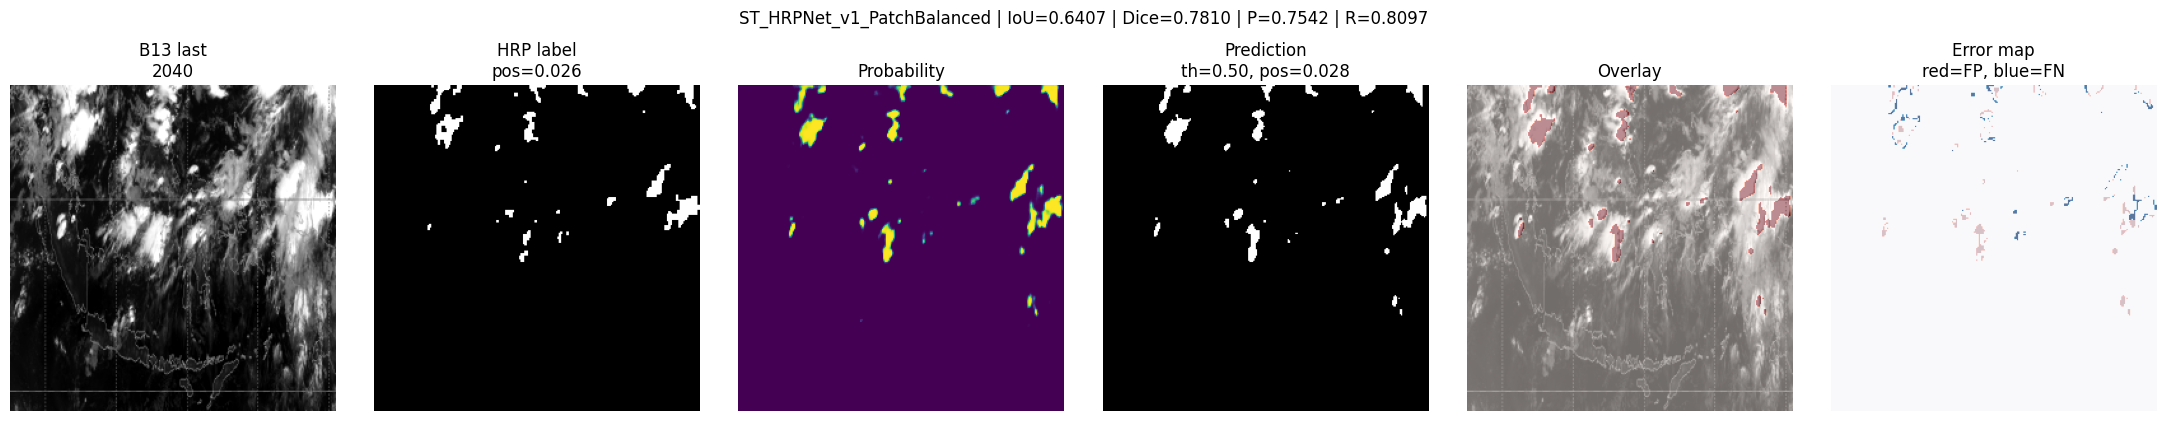

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_002.png


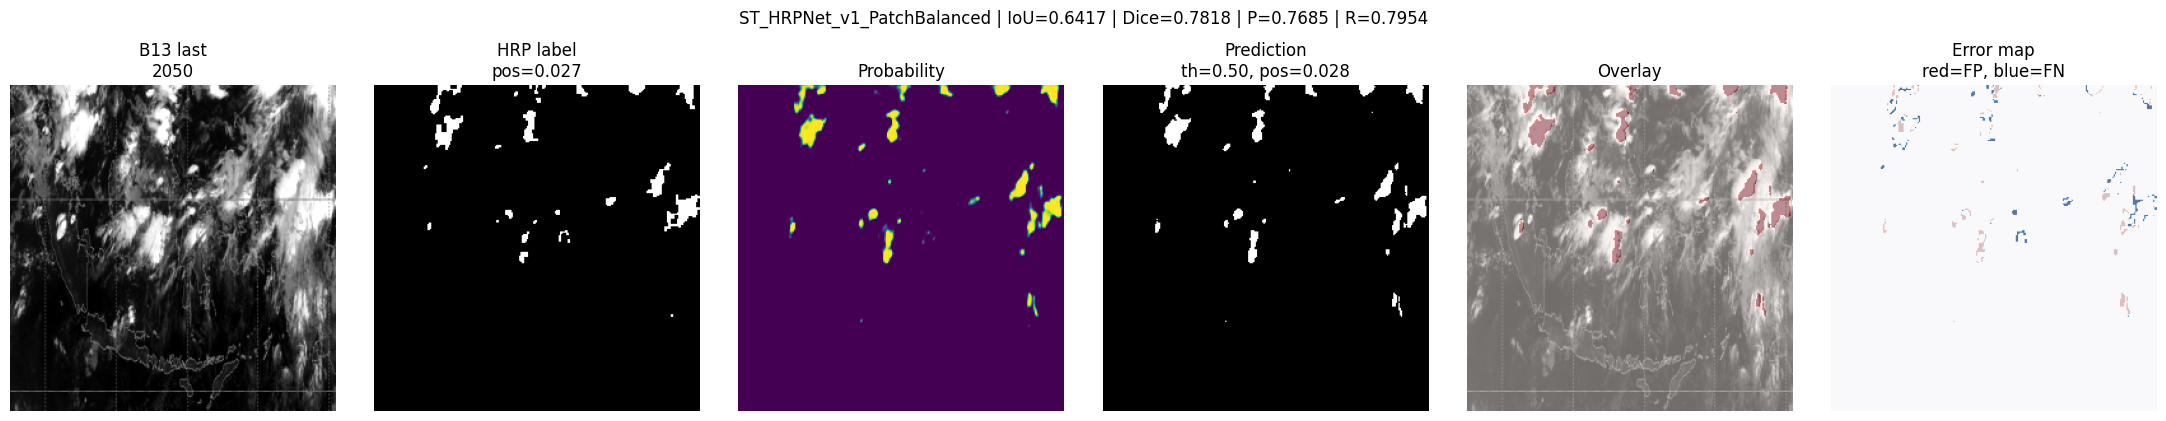

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_003.png


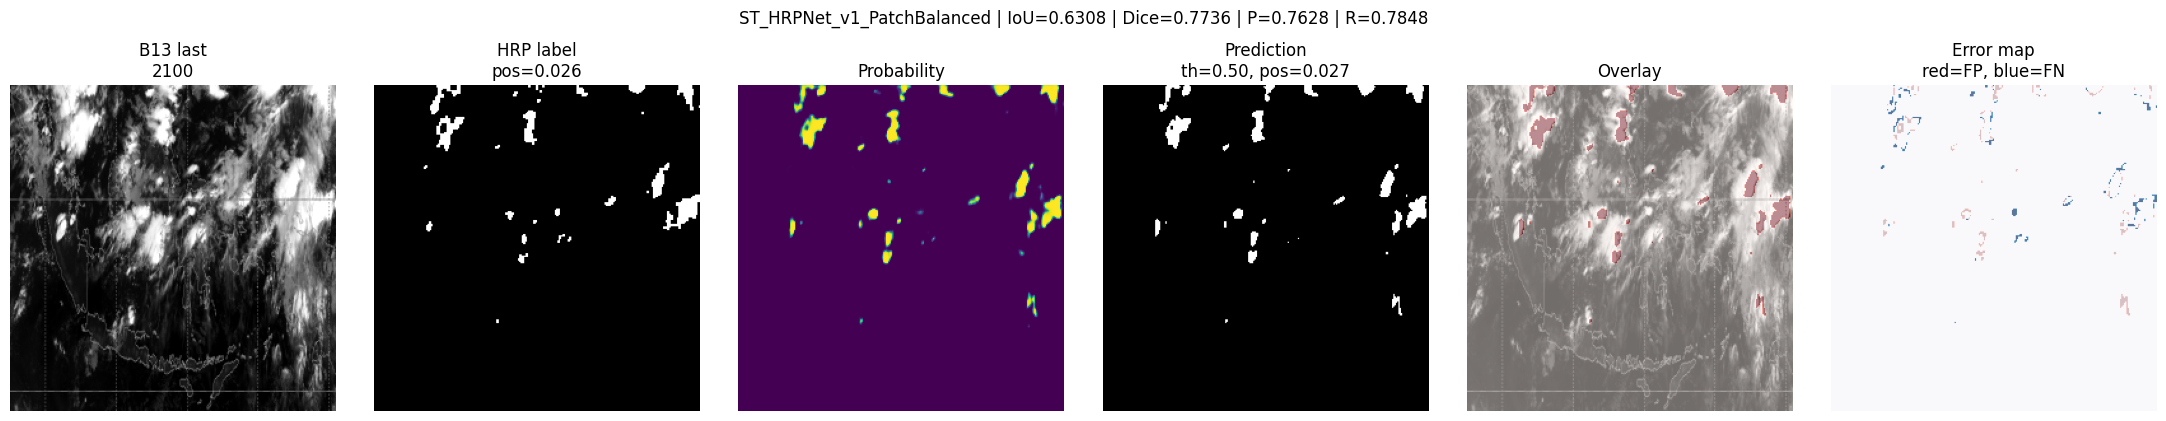

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_004.png


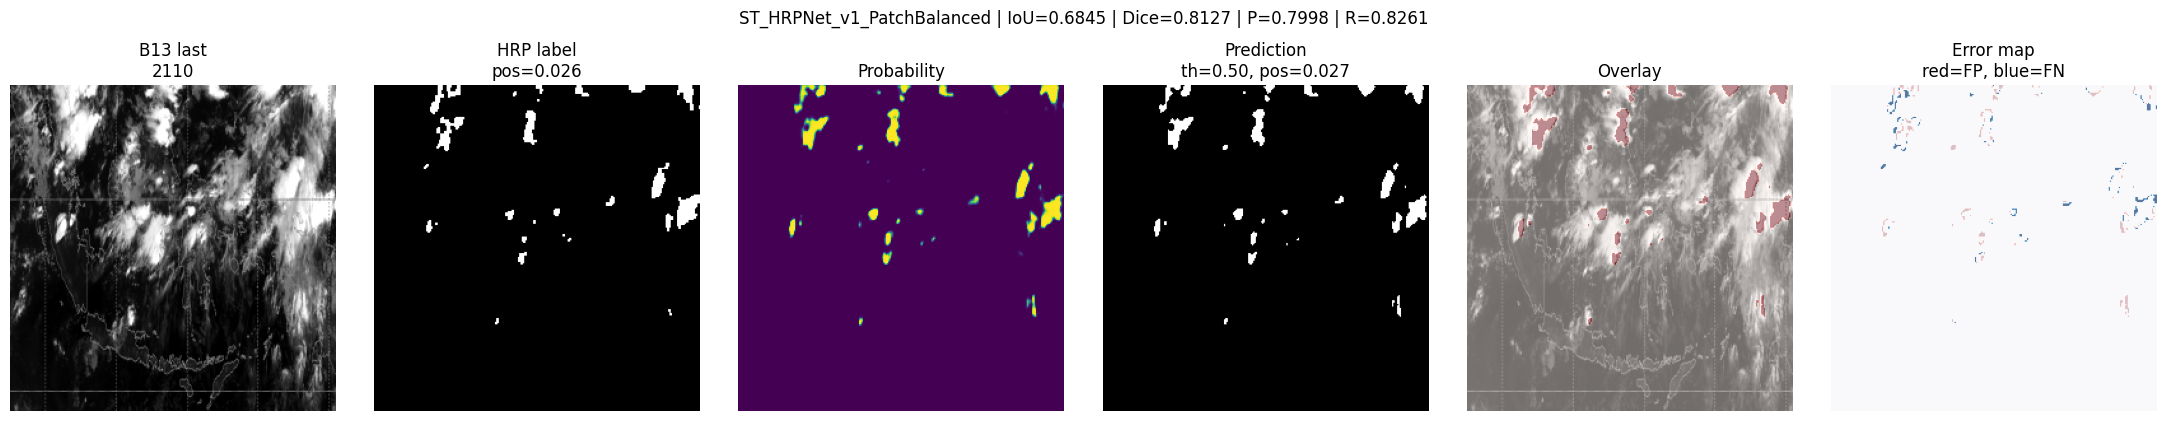

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_005.png


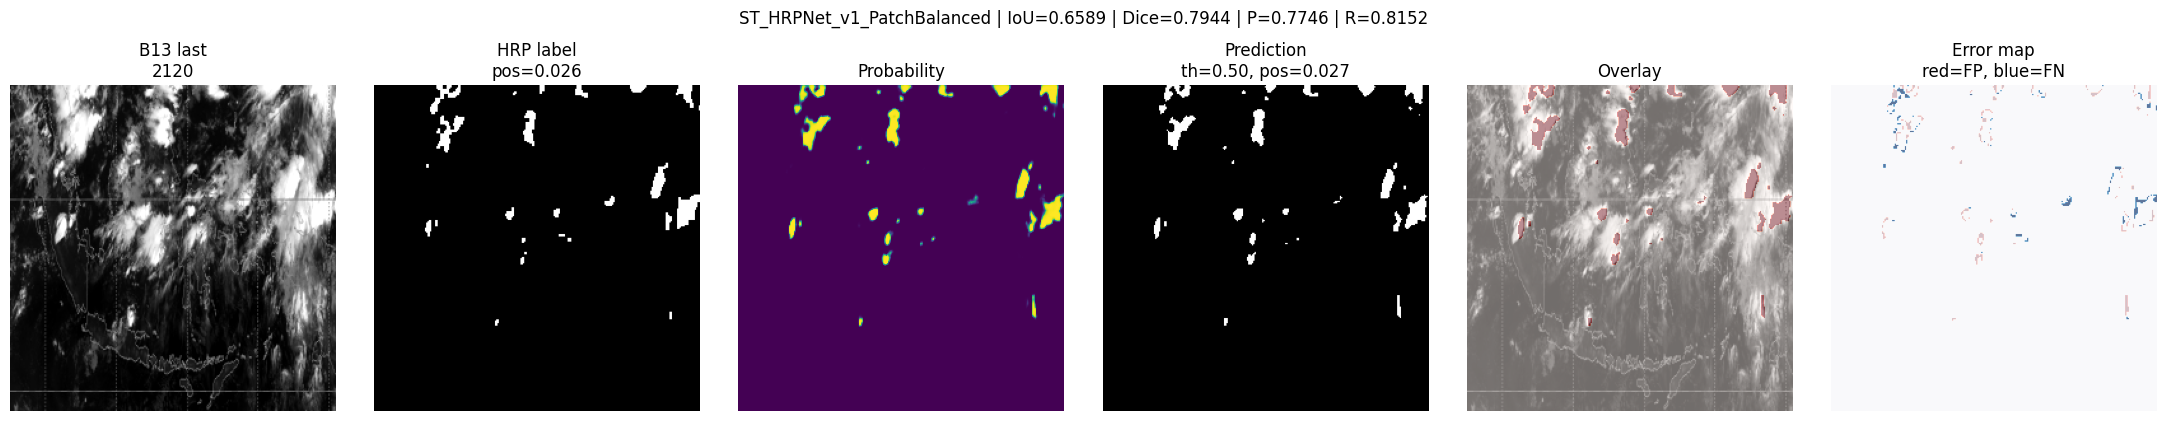

In [30]:
# ============================================================
# 15. VISUALISASI HASIL PREDIKSI FULL IMAGE — SAFE VERSION
# ============================================================

def ensure_results_df():
    global results_df

    if "results_df" in globals() and isinstance(results_df, pd.DataFrame) and len(results_df) > 0:
        return results_df

    candidates = [
        OUTPUT_DIR / "paper_ready_model_comparison_results_V2.csv",
        OUTPUT_DIR / "paper_ready_model_comparison_results.csv",
    ]

    for path in candidates:
        if Path(path).exists():
            print(f"results_df tidak ada di memory. Membaca dari: {path}")
            results_df = pd.read_csv(path)
            return results_df

    print("PERINGATAN: results_df belum tersedia dan file CSV evaluasi belum ditemukan.")
    print("Solusi terbaik: jalankan ulang cell #14 terlebih dahulu.")
    print("Untuk sementara visualisasi akan memakai threshold default 0.5.")

    results_df = pd.DataFrame([{
        "model": "ST_HRPNet_v1_PatchBalanced",
        "threshold": 0.5
    }])
    return results_df


def get_threshold_for_model(model_name, default_threshold=0.5):
    df = ensure_results_df()

    if "model" not in df.columns or "threshold" not in df.columns:
        return float(default_threshold)

    row = df[df["model"] == model_name]

    if row.empty:
        alt_names = [
            "ST_HRPNet_v1_PatchBalanced",
            "ST_HRPNet_v1",
            "ST_HRPNet_v1_PatchBalanced_V2"
        ]
        for alt in alt_names:
            row = df[df["model"] == alt]
            if not row.empty:
                print(f"Model {model_name} tidak ditemukan. Memakai threshold dari {alt}.")
                return float(row.iloc[0]["threshold"])

        print(f"Threshold untuk {model_name} tidak ditemukan. Pakai default {default_threshold}.")
        return float(default_threshold)

    th = row.iloc[0]["threshold"]
    if pd.isna(th):
        return float(default_threshold)

    return float(th)


def predict_for_visual(model_obj, X_one, input_type="sequence"):
    if input_type == "2d_last_frame":
        return model_obj.predict(X_one[:, -1, ...], batch_size=1, verbose=0)[0, ..., 0]
    return model_obj.predict(X_one, batch_size=1, verbose=0)[0, ..., 0]


def visualize_prediction(
    idx=0,
    model_obj=st_model,
    model_name="ST_HRPNet_v1_PatchBalanced",
    input_type="sequence",
    threshold=None,
    save=True
):
    if threshold is None:
        threshold = get_threshold_for_model(model_name)

    idx = int(min(max(idx, 0), len(X_test) - 1))

    prob = predict_for_visual(model_obj, X_test[idx:idx+1], input_type=input_type)
    prob = np.nan_to_num(prob, nan=0.0, posinf=1.0, neginf=0.0)
    prob = np.clip(prob, 0.0, 1.0)

    pred = (prob >= threshold).astype(np.float32)

    last_b13 = X_test[idx, -1, ..., INPUT_PRODUCTS.index("b13")]
    gt = y_test[idx, ..., 0].astype(np.float32)

    fp = ((pred == 1) & (gt == 0)).astype(np.float32)
    fn = ((pred == 0) & (gt == 1)).astype(np.float32)

    single_metrics = binary_metrics_np(gt, prob, threshold=threshold)

    fig = plt.figure(figsize=(22, 4))

    plt.subplot(1, 6, 1)
    plt.imshow(last_b13, cmap="gray")
    plt.title(f"B13 last\n{meta_test.iloc[idx]['target_time_code']}")
    plt.axis("off")

    plt.subplot(1, 6, 2)
    plt.imshow(gt, cmap="gray")
    plt.title(f"HRP label\npos={gt.mean():.3f}")
    plt.axis("off")

    plt.subplot(1, 6, 3)
    plt.imshow(prob, cmap="viridis")
    plt.title("Probability")
    plt.axis("off")

    plt.subplot(1, 6, 4)
    plt.imshow(pred, cmap="gray")
    plt.title(f"Prediction\nth={threshold:.2f}, pos={pred.mean():.3f}")
    plt.axis("off")

    plt.subplot(1, 6, 5)
    plt.imshow(last_b13, cmap="gray")
    plt.imshow(pred, alpha=0.45, cmap="Reds")
    plt.title("Overlay")
    plt.axis("off")

    plt.subplot(1, 6, 6)
    plt.imshow(fp, cmap="Reds", alpha=0.65)
    plt.imshow(fn, cmap="Blues", alpha=0.65)
    plt.title("Error map\nred=FP, blue=FN")
    plt.axis("off")

    plt.suptitle(
        f"{model_name} | IoU={single_metrics['iou']:.4f} | "
        f"Dice={single_metrics['dice_f1']:.4f} | "
        f"P={single_metrics['precision']:.4f} | R={single_metrics['recall']:.4f}",
        y=1.04
    )

    plt.tight_layout()

    if save:
        safe_model_name = re.sub(r"[^A-Za-z0-9_\\-]+", "_", str(model_name))
        out_path = OUTPUT_DIR / f"{safe_model_name}_prediction_visual_{idx:03d}.png"
        fig.savefig(out_path, dpi=220, bbox_inches="tight")
        print("Saved:", out_path)

    plt.show()


_ = ensure_results_df()
display(results_df)

for i in range(min(6, len(X_test))):
    visualize_prediction(i)

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_loss_curve.png


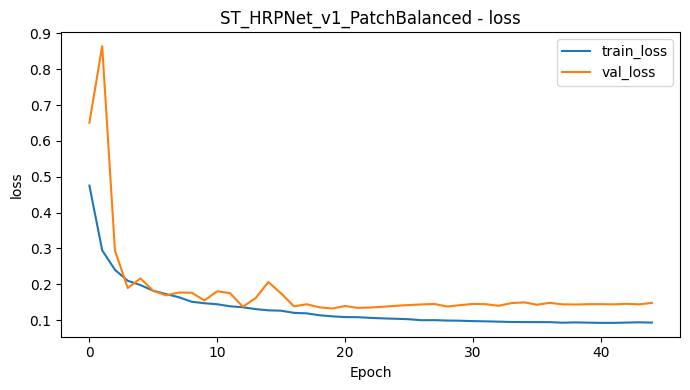

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_iou_coef_curve.png


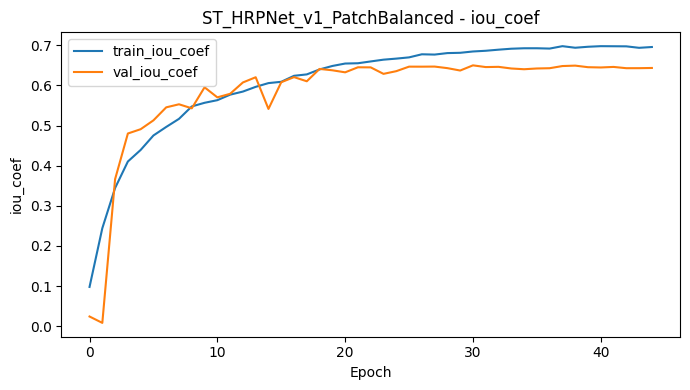

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_dice_coef_curve.png


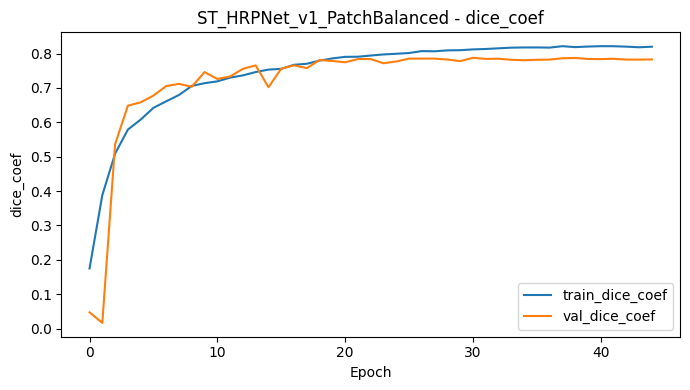

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_precision_at_05_curve.png


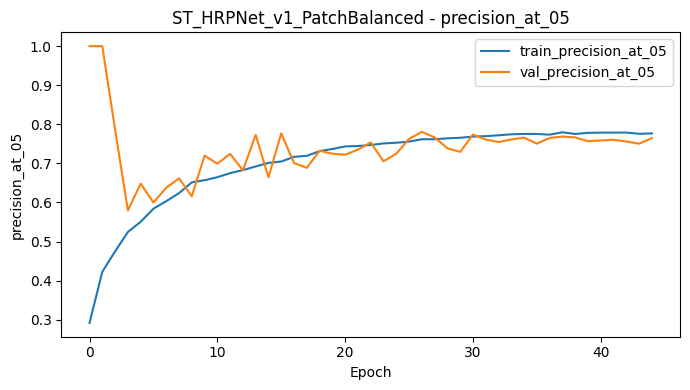

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_recall_at_05_curve.png


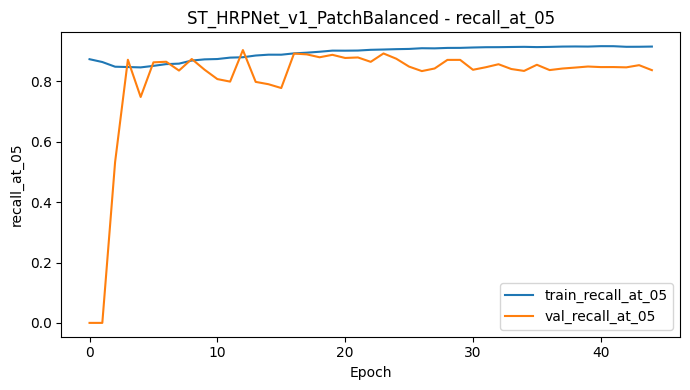

Experiment summary saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\experiment_summary_V2.json
{
  "paper_title": "ST-HRPNet v1: Spatiotemporal Learning for Himawari-Derived Heavy Rainfall Potential Segmentation over Indonesia",
  "project_name": "ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2",
  "dataset_tag": "jma_snapshot_20260529_0126UTC",
  "jma_list_url": "https://www.data.jma.go.jp/mscweb/data/himawari/list_r2w.html",
  "input_products": [
    "b13",
    "b08",
    "b07",
    "b03"
  ],
  "target_product": "hrp",
  "download_products": [
    "b13",
    "b08",
    "b07",
    "b03",
    "hrp",
    "snd"
  ],
  "sequence_length": 4,
  "image_size": [
    256,
    256
  ],
  "patch_size": 128,
  "n_raw_timestamps_valid": 142,
  "n_sequences": 139,
  "train_sequences": 97,
  "val_sequences": 21,
  "test_sequences": 21,
  "n_train_patches": 1800,
  "n_val_patches": 450,
  "positive_pixel_ratio_all_full": 0.020628895610570908,
  "positive

In [31]:
# ============================================================
# 16. TRAINING CURVES DAN EKSPERIMEN SUMMARY — ULTRA SAFE VERSION
# ============================================================

def safe_var(name, default=None):
    return globals().get(name, default)


def safe_len(name):
    obj = safe_var(name, None)
    if obj is None:
        return None
    try:
        return int(len(obj))
    except Exception:
        return None


def safe_mean(name):
    obj = safe_var(name, None)
    if obj is None:
        return None
    try:
        return float(np.asarray(obj).mean())
    except Exception:
        return None


def find_existing_file(candidates):
    for p in candidates:
        p = Path(p)
        if p.exists():
            return p
    return None


def resolve_results_path():
    """Pastikan results_path tersedia tanpa menyebabkan NameError."""
    global results_path

    if "results_path" in globals():
        try:
            if Path(results_path).exists():
                return Path(results_path)
        except Exception:
            pass

    candidates = [
        OUTPUT_DIR / "paper_ready_model_comparison_results_V2.csv",
        OUTPUT_DIR / "paper_ready_model_comparison_results.csv",
    ]

    found = find_existing_file(candidates)
    if found is not None:
        results_path = found
        return results_path

    results_path = OUTPUT_DIR / "paper_ready_model_comparison_results_V2.csv"
    print("PERINGATAN: file hasil evaluasi belum ditemukan.")
    print("Jalankan cell #14 sampai selesai agar CSV hasil evaluasi terbentuk.")
    print("Summary tetap dibuat dengan results_csv sebagai path rencana:", results_path)
    return results_path


def resolve_manifest_path():
    global manifest_path

    if "manifest_path" in globals():
        return Path(manifest_path)

    candidates = sorted(Path(MANIFEST_DIR).glob(f"manifest_{DATASET_TAG}.csv"))
    if candidates:
        manifest_path = candidates[-1]
        return manifest_path

    manifest_path = MANIFEST_DIR / f"manifest_{DATASET_TAG}.csv"
    return manifest_path


def resolve_meta_path():
    global meta_path

    if "meta_path" in globals():
        return Path(meta_path)

    meta_path = OUTPUT_DIR / "sequence_metadata.csv"
    return meta_path


def load_history_if_needed(model_name="ST_HRPNet_v1_PatchBalanced"):
    """Ambil training history dari memory atau CSV."""
    global st_history

    if "st_history" in globals() and isinstance(st_history, pd.DataFrame):
        return st_history

    candidates = [
        OUTPUT_DIR / model_name / f"{model_name}_history.csv",
        OUTPUT_DIR / model_name / f"{model_name}_training_log.csv",
    ]

    found = find_existing_file(candidates)
    if found is not None:
        print(f"st_history tidak ada di memory. Membaca history dari: {found}")
        st_history = pd.read_csv(found)
        return st_history

    print("PERINGATAN: st_history belum tersedia dan file history belum ditemukan.")
    print("Kurva training dilewati. Jalankan cell #12 jika ingin membuat kurva.")
    return pd.DataFrame()


def plot_history_safe(history_df, model_name):
    if history_df is None or len(history_df) == 0:
        print("History kosong. Plot training curve dilewati.")
        return

    for metric in ["loss", "iou_coef", "dice_coef", "precision_at_05", "recall_at_05"]:
        if metric not in history_df.columns:
            continue

        plt.figure(figsize=(7, 4))
        plt.plot(history_df[metric], label=f"train_{metric}")

        val_metric = f"val_{metric}"
        if val_metric in history_df.columns:
            plt.plot(history_df[val_metric], label=val_metric)

        plt.title(f"{model_name} - {metric}")
        plt.xlabel("Epoch")
        plt.ylabel(metric)
        plt.legend()
        plt.tight_layout()

        out_path = OUTPUT_DIR / f"{model_name}_{metric}_curve.png"
        plt.savefig(out_path, dpi=220, bbox_inches="tight")
        print("Saved:", out_path)
        plt.show()


# 1) Plot training curve secara aman.
history_df = load_history_if_needed("ST_HRPNet_v1_PatchBalanced")
plot_history_safe(history_df, "ST_HRPNet_v1_PatchBalanced")


# 2) Pastikan path penting aman.
resolved_results_path = resolve_results_path()
resolved_manifest_path = resolve_manifest_path()
resolved_meta_path = resolve_meta_path()


# 3) Load results_df jika memungkinkan.
if "results_df" not in globals():
    if Path(resolved_results_path).exists():
        results_df = pd.read_csv(resolved_results_path)
    else:
        results_df = pd.DataFrame()


# 4) Ringkasan best model jika tabel evaluasi tersedia.
best_model_summary = {}

if isinstance(results_df, pd.DataFrame) and len(results_df) > 0:
    try:
        best_row = results_df.iloc[0].to_dict()

        def safe_float_from_row(key):
            val = best_row.get(key, None)
            if val is None or pd.isna(val):
                return None
            return float(val)

        best_model_summary = {
            "best_model": best_row.get("model", None),
            "best_iou": safe_float_from_row("iou"),
            "best_dice_f1": safe_float_from_row("dice_f1"),
            "best_precision": safe_float_from_row("precision"),
            "best_recall": safe_float_from_row("recall"),
            "best_mcc": safe_float_from_row("mcc"),
            "best_pr_auc": safe_float_from_row("pr_auc"),
            "best_threshold": safe_float_from_row("threshold"),
        }

    except Exception as e:
        print("Peringatan: gagal membuat best_model_summary:", e)
        best_model_summary = {}


# 5) Buat dictionary summary.
# PENTING: Jangan pernah meletakkan if statement di dalam dictionary.
experiment_summary = {
    "paper_title": safe_var("PAPER_TITLE"),
    "project_name": safe_var("PROJECT_NAME"),
    "dataset_tag": safe_var("DATASET_TAG"),
    "jma_list_url": safe_var("JMA_LIST_URL"),
    "input_products": safe_var("INPUT_PRODUCTS"),
    "target_product": safe_var("TARGET_PRODUCT"),
    "download_products": safe_var("DOWNLOAD_PRODUCTS"),
    "sequence_length": safe_var("SEQ_LEN"),
    "image_size": safe_var("IMG_SIZE"),
    "patch_size": safe_var("PATCH_SIZE"),
    "n_raw_timestamps_valid": safe_len("valid_manifest"),
    "n_sequences": safe_len("X"),
    "train_sequences": safe_len("X_train"),
    "val_sequences": safe_len("X_val"),
    "test_sequences": safe_len("X_test"),
    "n_train_patches": safe_len("X_train_patch"),
    "n_val_patches": safe_len("X_val_patch"),
    "positive_pixel_ratio_all_full": safe_mean("y"),
    "positive_pixel_ratio_train_full": safe_mean("y_train"),
    "positive_pixel_ratio_val_full": safe_mean("y_val"),
    "positive_pixel_ratio_test_full": safe_mean("y_test"),
    "positive_pixel_ratio_train_patch": safe_mean("y_train_patch"),
    "positive_pixel_ratio_val_patch": safe_mean("y_val_patch"),
    "loss_pos_weight": float(safe_var("LOSS_POS_WEIGHT")) if safe_var("LOSS_POS_WEIGHT") is not None else None,
    "results_csv": str(resolved_results_path),
    "manifest_csv": str(resolved_manifest_path),
    "sequence_metadata_csv": str(resolved_meta_path),
    "best_model_summary": best_model_summary,
}


# 6) Simpan summary eksperimen.
summary_path = OUTPUT_DIR / "experiment_summary_V2.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(experiment_summary, f, indent=2)

print("Experiment summary saved:", summary_path)
print(json.dumps(experiment_summary, indent=2))


## 17. TAAC extension experiments

The following cells extend the original experiment for a **Theoretical and Applied Climatology** submission.  
They do not remove the original experiment. Instead, they add:

1. **Threshold sensitivity analysis** to show whether the constrained threshold is stable.
2. **Ablation study** to quantify the contribution of patch-balanced training, false-positive-aware loss, and constrained thresholding.
3. **Optional independent precipitation validation** using externally prepared GPM IMERG, GSMaP, radar, or rain-gauge-derived masks.
4. **Event-based case analysis** for meteorological interpretation.

> Important: the independent precipitation validation cell is optional and will be skipped safely unless precipitation masks or precipitation grids are provided in the expected folder.


In [24]:
from pathlib import Path

BASE_DIR = Path(r"D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program")

RESULTS_DIR = BASE_DIR / "results"
FIGURES_DIR = BASE_DIR / "figures"
MODELS_DIR = BASE_DIR / "models"
EXTERNAL_PRECIP_DIR = BASE_DIR / "external_precip_validation"

for d in [RESULTS_DIR, FIGURES_DIR, MODELS_DIR, EXTERNAL_PRECIP_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Base directory:", BASE_DIR)
print("Results directory:", RESULTS_DIR)
print("Figures directory:", FIGURES_DIR)
print("Models directory:", MODELS_DIR)
print("External precipitation validation directory:", EXTERNAL_PRECIP_DIR)

Base directory: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program
Results directory: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\results
Figures directory: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\figures
Models directory: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\models
External precipitation validation directory: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\external_precip_validation


In [30]:
# ============================================================
# LOAD ST-HRPNET WEIGHTS - WITHOUT COMPILE_MODEL
# ============================================================

from pathlib import Path
import numpy as np

BASE_DIR = Path(r"D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program")

OUTPUT_DIR = (
    BASE_DIR
    / "outputs"
    / "ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2"
    / "jma_snapshot_20260529_0126UTC"
)

ST_WEIGHTS = (
    OUTPUT_DIR
    / "ST_HRPNet_v1_PatchBalanced"
    / "ST_HRPNet_v1_PatchBalanced_best.weights.h5"
)

print("Checking weights:", ST_WEIGHTS)

if not ST_WEIGHTS.exists():
    raise FileNotFoundError(f"Bobot model tidak ditemukan: {ST_WEIGHTS}")

if "build_st_hrpnet_v1_patchbalanced" not in globals():
    raise RuntimeError(
        "Fungsi build_st_hrpnet_v1_patchbalanced belum tersedia. "
        "Jalankan dulu cell model architecture / ST-HRPNet v1 sebelum load weights."
    )

# Tidak perlu compile untuk load_weights dan predict
st_model = build_st_hrpnet_v1_patchbalanced()
st_model.load_weights(str(ST_WEIGHTS))

print("ST-HRPNet weights loaded successfully.")
print("st_model ready:", type(st_model))

Checking weights: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced\ST_HRPNet_v1_PatchBalanced_best.weights.h5
ST-HRPNet weights loaded successfully.
st_model ready: <class 'keras.src.engine.functional.Functional'>


In [31]:
# ============================================================
# 17A. TAAC EXTENSION CONFIGURATION - FIXED
# ============================================================

from pathlib import Path
import os

PAPER_TITLE_TAAC = (
    "Himawari-derived heavy rainfall potential segmentation over Indonesia "
    "using an imbalance-aware spatiotemporal deep learning framework"
)

# Folder utama sesuai lokasi Bapak
BASE_DIR = Path(r"D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program")

# Folder output utama
OUTPUT_DIR = BASE_DIR / "outputs"

# Folder khusus eksperimen tambahan TAAC
TAAC_OUTPUT_DIR = OUTPUT_DIR / "TAAC_extension_experiments"

# Folder pendukung
RESULTS_DIR = TAAC_OUTPUT_DIR / "results"
FIGURES_DIR = TAAC_OUTPUT_DIR / "figures"
MODELS_DIR = TAAC_OUTPUT_DIR / "models"
TABLES_DIR = TAAC_OUTPUT_DIR / "tables"
EXTERNAL_PRECIP_DIR = BASE_DIR / "external_precip_validation"

# Buat semua folder jika belum ada
for d in [
    OUTPUT_DIR,
    TAAC_OUTPUT_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    TABLES_DIR,
    EXTERNAL_PRECIP_DIR
]:
    d.mkdir(parents=True, exist_ok=True)

# Run switches
RUN_THRESHOLD_SENSITIVITY = True
RUN_ABLATION_STUDY = True
RUN_EXTERNAL_PRECIP_VALIDATION = True
RUN_EVENT_CASE_ANALYSIS = True
EXPORT_MANUSCRIPT_SUMMARY = True

print("TAAC experiment configuration is ready.")
print("BASE_DIR:", BASE_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("TAAC_OUTPUT_DIR:", TAAC_OUTPUT_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("FIGURES_DIR:", FIGURES_DIR)
print("TABLES_DIR:", TABLES_DIR)
print("EXTERNAL_PRECIP_DIR:", EXTERNAL_PRECIP_DIR)

TAAC experiment configuration is ready.
BASE_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program
OUTPUT_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs
TAAC_OUTPUT_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments
RESULTS_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\results
FIGURES_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\figures
TABLES_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\tables
EXTERNAL_PRECIP_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\external_precip_validation


In [32]:

# ============================================================
# 17A. TAAC EXTENSION CONFIGURATION
# ============================================================

PAPER_TITLE_TAAC = "Himawari-derived heavy rainfall potential segmentation over Indonesia using an imbalance-aware spatiotemporal deep learning framework"

TAAC_OUTPUT_DIR = OUTPUT_DIR / "TAAC_extension_experiments"
TAAC_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Run switches.
RUN_TAAC_THRESHOLD_SENSITIVITY = True
RUN_TAAC_ABLATION = True

# Optional. Keep False first if compute is limited.
RUN_TAAC_NOSKIP_ABLATION = False

# Optional independent precipitation validation.
# This will run only if external precipitation data are found.
RUN_TAAC_PRECIP_VALIDATION = True

# Ablation training setting. Reduce for quick checking; increase for paper-grade results.
TAAC_ABLATION_EPOCHS = 35
TAAC_REUSE_EXISTING_ABLATION_WEIGHTS = True

# Independent precipitation validation input folder.
# Accepted inputs:
# 1) external_precip_validation/precip_test_masks_256.npy
#    Shape must be (len(X_test), 256, 256, 1) or (len(X_test), 256, 256).
# 2) external_precip_validation/masks_by_time/<target_time_code>.png
# 3) external_precip_validation/precip_grid.csv
#    Required columns: target_time_code, lon, lat, precip
# 4) external_precip_validation/netcdf/*.nc
#    Optional xarray-based loader for GPM/GSMaP-like grids.
EXTERNAL_PRECIP_ROOT = Path("external_precip_validation")
PRECIP_MASK_NPY = EXTERNAL_PRECIP_ROOT / "precip_test_masks_256.npy"
PRECIP_MASK_DIR = EXTERNAL_PRECIP_ROOT / "masks_by_time"
PRECIP_GRID_CSV = EXTERNAL_PRECIP_ROOT / "precip_grid.csv"
PRECIP_NETCDF_DIR = EXTERNAL_PRECIP_ROOT / "netcdf"

# Threshold for converting independent precipitation product to binary heavy-rainfall occurrence.
# Adjust according to the product temporal resolution and local meteorological definition.
PRECIP_THRESHOLD = 10.0
PRECIP_VALUE_COLUMN = "precip"

print("TAAC extension title:", PAPER_TITLE_TAAC)
print("TAAC output dir:", TAAC_OUTPUT_DIR)
print("Run ablation:", RUN_TAAC_ABLATION)
print("Run threshold sensitivity:", RUN_TAAC_THRESHOLD_SENSITIVITY)
print("Run precipitation validation:", RUN_TAAC_PRECIP_VALIDATION)


TAAC extension title: Himawari-derived heavy rainfall potential segmentation over Indonesia using an imbalance-aware spatiotemporal deep learning framework
TAAC output dir: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments
Run ablation: True
Run threshold sensitivity: True
Run precipitation validation: True


In [33]:
# ============================================================
# 17B. COMMON HELPERS FOR TAAC EXTENSION - FIXED SAFE VERSION
# ============================================================

import os, math, time, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc

warnings.filterwarnings("ignore")

if "BASE_DIR" not in globals():
    BASE_DIR = Path(r"D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program")

if "OUTPUT_DIR" not in globals():
    OUTPUT_DIR = BASE_DIR / "outputs"

if "TAAC_OUTPUT_DIR" not in globals():
    TAAC_OUTPUT_DIR = OUTPUT_DIR / "TAAC_extension_experiments"

RESULTS_DIR = TAAC_OUTPUT_DIR / "results"
FIGURES_DIR = TAAC_OUTPUT_DIR / "figures"
TABLES_DIR = TAAC_OUTPUT_DIR / "tables"
EXTERNAL_PRECIP_DIR = BASE_DIR / "external_precip_validation"

for d in [OUTPUT_DIR, TAAC_OUTPUT_DIR, RESULTS_DIR, FIGURES_DIR, TABLES_DIR, EXTERNAL_PRECIP_DIR]:
    Path(d).mkdir(parents=True, exist_ok=True)

if "BATCH_SIZE" not in globals():
    BATCH_SIZE = 8

if "binary_metrics_np" not in globals():
    def binary_metrics_np(y_true, y_prob, threshold=0.5):
        yt = (np.asarray(y_true).reshape(-1) >= 0.5).astype(np.uint8)
        yp_prob = np.asarray(y_prob).reshape(-1).astype(np.float32)
        yp = (yp_prob >= threshold).astype(np.uint8)

        tp = np.sum((yt == 1) & (yp == 1))
        fp = np.sum((yt == 0) & (yp == 1))
        fn = np.sum((yt == 1) & (yp == 0))
        tn = np.sum((yt == 0) & (yp == 0))

        precision = tp / (tp + fp + 1e-7)
        recall = tp / (tp + fn + 1e-7)
        specificity = tn / (tn + fp + 1e-7)
        fpr = fp / (fp + tn + 1e-7)
        dice = 2 * tp / (2 * tp + fp + fn + 1e-7)
        iou = tp / (tp + fp + fn + 1e-7)
        accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-7)
        balanced_accuracy = 0.5 * (recall + specificity)

        denom = math.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)) + 1e-7
        mcc = ((tp * tn) - (fp * fn)) / denom

        return {
            "threshold": float(threshold),
            "iou": float(iou),
            "dice_f1": float(dice),
            "precision": float(precision),
            "recall": float(recall),
            "specificity": float(specificity),
            "fpr": float(fpr),
            "accuracy": float(accuracy),
            "balanced_accuracy": float(balanced_accuracy),
            "mcc": float(mcc),
            "actual_positive_ratio": float(yt.mean()),
            "predicted_positive_ratio": float(yp.mean()),
            "tp": int(tp),
            "fp": int(fp),
            "fn": int(fn),
            "tn": int(tn),
        }

if "pr_auc_score_np" not in globals():
    def pr_auc_score_np(y_true, y_prob):
        yt = (np.asarray(y_true).reshape(-1) >= 0.5).astype(np.uint8)
        yp = np.asarray(y_prob).reshape(-1).astype(np.float32)

        if len(np.unique(yt)) < 2:
            return np.nan

        precision, recall, _ = precision_recall_curve(yt, yp)
        return float(auc(recall, precision))

if "predict_full" not in globals():
    def predict_full(model, X_arr, input_type="sequence", batch_size=BATCH_SIZE, verbose=0):
        if input_type == "2d_last_frame":
            return model.predict(X_arr[:, -1, ...], batch_size=batch_size, verbose=verbose)
        return model.predict(X_arr, batch_size=batch_size, verbose=verbose)

if "select_threshold_constrained" not in globals():
    def select_threshold_constrained(y_true, y_prob, model_name="model"):
        actual_ratio = float((np.asarray(y_true).reshape(-1) >= 0.5).mean())
        thresholds = np.arange(0.02, 0.981, 0.01)
        rows = []

        for th in thresholds:
            m = binary_metrics_np(y_true, y_prob, threshold=th)
            pred_ratio = m["predicted_positive_ratio"]
            ratio_penalty = abs(np.log((pred_ratio + 1e-7) / (actual_ratio + 1e-7)))

            m["positive_ratio_penalty"] = float(ratio_penalty)
            m["model"] = model_name
            m["is_ratio_valid"] = bool(
                (pred_ratio >= 0.25 * actual_ratio) and
                (pred_ratio <= 4.00 * actual_ratio)
            )
            m["selection_score"] = (
                m["iou"]
                + 0.20 * m["dice_f1"]
                + 0.10 * m["balanced_accuracy"]
                + 0.10 * m["mcc"]
                - 0.025 * ratio_penalty
            )
            rows.append(m)

        df = pd.DataFrame(rows)
        valid = df[df["is_ratio_valid"]].copy()

        if len(valid) > 0:
            best_idx = valid["selection_score"].idxmax()
        else:
            best_idx = df["selection_score"].idxmax()

        best_th = float(df.loc[best_idx, "threshold"])
        return best_th, df

# ------------------------------------------------------------
# Bind alias jika nama variabel berbeda
# ------------------------------------------------------------

alias_map = {
    "X_val": ["X_val", "x_val", "X_valid", "x_valid", "val_X"],
    "y_val": ["y_val", "Y_val", "y_valid", "Y_valid", "val_y"],
    "X_test": ["X_test", "x_test", "test_X"],
    "y_test": ["y_test", "Y_test", "test_y"],
    "st_model": ["st_model", "ST_model", "st_hrpnet_model", "model_st_hrpnet", "best_model", "model"],
}

missing_core = []

for target, aliases in alias_map.items():
    found = None
    for a in aliases:
        if a in globals():
            found = globals()[a]
            globals()[target] = found
            break

    if found is None:
        missing_core.append(target)

print("=" * 80)
print("TAAC helper status")
print("=" * 80)
print("BASE_DIR:", BASE_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("TAAC_OUTPUT_DIR:", TAAC_OUTPUT_DIR)

if missing_core:
    print("\nBELUM SIAP. Variabel utama berikut belum tersedia:")
    for m in missing_core:
        print("-", m)

    print("\nPenyebab:")
    print("Notebook belum dijalankan sampai temporal split, training/load model, dan evaluasi utama.")

    print("\nSolusi:")
    print("Jalankan notebook dari awal sampai evaluasi utama selesai, lalu ulangi 17A dan 17B.")

    raise RuntimeError(
        "TAAC extension belum bisa dilanjutkan karena variabel utama belum tersedia."
    )

print("\nSIAP. Semua variabel utama tersedia.")
print("X_val :", getattr(X_val, "shape", type(X_val)))
print("y_val :", getattr(y_val, "shape", type(y_val)))
print("X_test:", getattr(X_test, "shape", type(X_test)))
print("y_test:", getattr(y_test, "shape", type(y_test)))
print("st_model:", type(st_model))
print("\nTAAC helper functions ready.")

TAAC helper status
BASE_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program
OUTPUT_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs
TAAC_OUTPUT_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments

SIAP. Semua variabel utama tersedia.
X_val : (21, 4, 256, 256, 4)
y_val : (21, 256, 256, 1)
X_test: (21, 4, 256, 256, 4)
y_test: (21, 256, 256, 1)
st_model: <class 'keras.src.engine.functional.Functional'>

TAAC helper functions ready.


In [35]:
print("y_val:", y_val.shape)
print("st_val_prob:", st_val_prob.shape)
print("y_test:", y_test.shape)
print("st_test_prob:", st_test_prob.shape)

y_val: (21, 256, 256, 1)
st_val_prob: (21, 256, 256, 1)
y_test: (21, 256, 256, 1)
st_test_prob: (21, 256, 256, 1)


In [36]:
# ============================================================
# FIX: SAFE BINARY METRICS TO AVOID MCC OVERFLOW
# Run this before 17C
# ============================================================

import numpy as np
import math

def binary_metrics_np(y_true, y_prob, threshold=0.5):
    yt = (np.asarray(y_true).reshape(-1) >= 0.5).astype(np.uint8)

    yp_prob = np.asarray(y_prob).reshape(-1).astype(np.float32)
    yp_prob = np.nan_to_num(yp_prob, nan=0.0, posinf=1.0, neginf=0.0)
    yp_prob = np.clip(yp_prob, 0.0, 1.0)

    if yt.shape[0] != yp_prob.shape[0]:
        raise ValueError(
            f"Shape mismatch after flatten: y_true={yt.shape}, y_prob={yp_prob.shape}. "
            "Pastikan y_test/y_val dan probability map memiliki ukuran yang sama."
        )

    yp = (yp_prob >= float(threshold)).astype(np.uint8)

    # Gunakan Python int agar tidak overflow seperti NumPy int64/uint64
    tp = int(np.count_nonzero((yt == 1) & (yp == 1)))
    fp = int(np.count_nonzero((yt == 0) & (yp == 1)))
    fn = int(np.count_nonzero((yt == 1) & (yp == 0)))
    tn = int(np.count_nonzero((yt == 0) & (yp == 0)))

    tp_f = float(tp)
    fp_f = float(fp)
    fn_f = float(fn)
    tn_f = float(tn)

    eps = 1e-7

    precision = tp_f / (tp_f + fp_f + eps)
    recall = tp_f / (tp_f + fn_f + eps)
    specificity = tn_f / (tn_f + fp_f + eps)
    fpr = fp_f / (fp_f + tn_f + eps)
    dice = (2.0 * tp_f) / (2.0 * tp_f + fp_f + fn_f + eps)
    iou = tp_f / (tp_f + fp_f + fn_f + eps)
    accuracy = (tp_f + tn_f) / (tp_f + tn_f + fp_f + fn_f + eps)
    balanced_accuracy = 0.5 * (recall + specificity)

    # MCC denominator dibuat float aman
    denom = (tp_f + fp_f) * (tp_f + fn_f) * (tn_f + fp_f) * (tn_f + fn_f)

    if denom <= 0:
        mcc = 0.0
    else:
        mcc = ((tp_f * tn_f) - (fp_f * fn_f)) / (math.sqrt(denom) + eps)

    return {
        "threshold": float(threshold),
        "iou": float(iou),
        "dice_f1": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "specificity": float(specificity),
        "fpr": float(fpr),
        "accuracy": float(accuracy),
        "balanced_accuracy": float(balanced_accuracy),
        "mcc": float(mcc),
        "actual_positive_ratio": float(yt.mean()),
        "predicted_positive_ratio": float(yp.mean()),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
    }

print("binary_metrics_np fixed. Safe MCC calculation is ready.")

binary_metrics_np fixed. Safe MCC calculation is ready.


In [38]:
# ============================================================
# FIX BEFORE 17D: REBUILD train_model FUNCTION
# ============================================================

import time
from pathlib import Path
import pandas as pd
import tensorflow as tf
from tensorflow import keras

# Pastikan OUTPUT_DIR ada
if "BASE_DIR" not in globals():
    BASE_DIR = Path(r"D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program")

if "OUTPUT_DIR" not in globals():
    OUTPUT_DIR = BASE_DIR / "outputs" / "TAAC_extension_experiments"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Jika BATCH_SIZE belum ada
if "BATCH_SIZE" not in globals():
    BATCH_SIZE = 8

# Jika EPOCHS_ABLATION belum ada, pakai nilai aman
if "EPOCHS_ABLATION" not in globals():
    EPOCHS_ABLATION = 20

# Jika fungsi compile_model belum ada, buat fallback aman
if "compile_model" not in globals():
    def compile_model(model, lr=None):
        if lr is None:
            lr = globals().get("LEARNING_RATE", 1e-4)

        # Pakai loss utama jika tersedia
        if "combined_hrp_loss" in globals():
            loss_fn = combined_hrp_loss
        else:
            loss_fn = "binary_crossentropy"

        metrics_list = []

        if "dice_coef" in globals():
            metrics_list.append(dice_coef)

        if "iou_coef" in globals():
            metrics_list.append(iou_coef)

        if "precision_at_05" in globals():
            metrics_list.append(precision_at_05)

        if "recall_at_05" in globals():
            metrics_list.append(recall_at_05)

        if not metrics_list:
            metrics_list = ["accuracy"]

        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=lr),
            loss=loss_fn,
            metrics=metrics_list,
        )

        return model


def train_model(model, train_data, val_data, name, epochs=None):
    """
    Training function untuk eksperimen utama/ablation.
    Aman untuk Keras 2.13+ dan menyimpan best weights.
    """

    if epochs is None:
        epochs = globals().get("EPOCHS_ABLATION", 20)

    model_dir = OUTPUT_DIR / name
    model_dir.mkdir(parents=True, exist_ok=True)

    ckpt_path = model_dir / f"{name}_best.weights.h5"
    history_path = model_dir / f"{name}_history.csv"
    log_path = model_dir / f"{name}_training_log.csv"

    # Compile jika model belum compile
    try:
        _ = model.optimizer
        if model.optimizer is None:
            model = compile_model(model)
    except Exception:
        model = compile_model(model)

    # Tentukan monitor metric
    metric_names = []
    try:
        metric_names = [m.name if hasattr(m, "name") else str(m) for m in model.metrics]
    except Exception:
        metric_names = []

    if any("iou" in str(m).lower() for m in metric_names):
        monitor_metric = "val_iou_coef"
        monitor_mode = "max"
    else:
        monitor_metric = "val_loss"
        monitor_mode = "min"

    print("=" * 80)
    print("Training model:", name)
    print("Output dir:", model_dir)
    print("Checkpoint:", ckpt_path)
    print("Monitor:", monitor_metric)
    print("=" * 80)

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            filepath=str(ckpt_path),
            monitor=monitor_metric,
            mode=monitor_mode,
            save_best_only=True,
            save_weights_only=True,
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor=monitor_metric,
            mode=monitor_mode,
            patience=10,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=1,
        ),
        keras.callbacks.CSVLogger(
            filename=str(log_path),
            append=False,
        ),
    ]

    start_time = time.time()

    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=int(epochs),
        callbacks=callbacks,
        verbose=1,
    )

    elapsed = time.time() - start_time

    hist_df = pd.DataFrame(history.history)
    hist_df["epoch"] = range(1, len(hist_df) + 1)
    hist_df["training_time_seconds_total"] = elapsed
    hist_df.to_csv(history_path, index=False)

    # Load best weights jika tersimpan
    if ckpt_path.exists():
        model.load_weights(str(ckpt_path))
        print("Best weights loaded:", ckpt_path)
    else:
        print("Warning: checkpoint tidak ditemukan. Model memakai bobot terakhir.")

    print("History saved:", history_path)
    print("Training log saved:", log_path)
    print("Training time seconds:", round(elapsed, 2))

    return model, history, model_dir


print("train_model fixed and ready.")

train_model fixed and ready.


Preparing random-patch data for non-balanced ablation...


Random patches: 100%|██████████| 450/450 [00:00<00:00, 223338.87it/s]

Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\ablation_patch_sampling_summary.csv


,split,n,positive_pixel_ratio
0,train_random_patch,1800,0.000405
1,val_random_patch,450,0.000806
2,train_patch_balanced,1800,0.005837
3,val_patch_balanced,450,0.005994


Training ablation model: Ablation_A_RandomPatch_WBCE_Dice_NoFP
Training model: Ablation_A_RandomPatch_WBCE_Dice_NoFP
Output dir: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\Ablation_A_RandomPatch_WBCE_Dice_NoFP
Checkpoint: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\Ablation_A_RandomPatch_WBCE_Dice_NoFP\Ablation_A_RandomPatch_WBCE_Dice_NoFP_best.weights.h5
Monitor: val_loss
Epoch 1/35
225/225 [==============================] - ETA: 0s - loss: 0.5002 - dice_coef: 0.0012 - iou_coef: 5.7925e-04 - precision_at_05: 0.1026 - recall_at_05: 0.4882
Epoch 1: val_loss improved from inf to 0.54717, saving model to D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\Ablation_A_RandomPatch_WBCE_Dice_NoFP\Ablation_A_RandomPatch_WBCE_Dice_NoFP_best.weights.h5
225/225 [==============================] - 162s 699ms/step - loss: 0.5002 - dice_coef: 0.0012 - iou_coef: 5.7925e-04 - precision_at_05: 0.1026 - recall_at_05: 0.4882 - val_loss: 0.5472 - val_dice_coef

,model,ablation_component,threshold_mode,threshold,iou,dice_f1,precision,recall,specificity,fpr,balanced_accuracy,mcc,pr_auc,actual_positive_ratio,predicted_positive_ratio,tp,fp,fn,tn,accuracy
0,Ablation_A_RandomPatch_WBCE_Dice_NoFP,random patches + WBCE-Dice loss + fixed threshold,fixed,0.50,0.261996,0.415209,0.277197,0.826918,0.993754,0.006246,0.910336,0.476523,0.354111,0.002888,0.008616,3287,8571,688,1363710,0.993272
1,Ablation_B_PatchBalanced_WBCE_Dice_NoFP,patch-balanced + WBCE-Dice loss + fixed threshold,fixed,0.50,0.055943,0.105958,0.161924,0.078742,0.998819,0.001181,0.538781,0.111142,0.163516,0.002888,0.001405,313,1620,3662,1370661,0.996162
2,Ablation_C_PatchBalanced_FPaware_Fixed05,patch-balanced + FP-aware loss + fixed threshold,fixed,0.50,0.135459,0.238598,0.144224,0.690314,0.988135,0.011865,0.839225,0.311822,0.219009,0.002888,0.013824,2744,16282,1231,1355999,0.987275
3,Ablation_D_FullFramework_ConstrainedThreshold,patch-balanced + FP-aware loss + constrained t...,constrained,0.98,0.165532,0.284046,0.215617,0.416101,0.995615,0.004385,0.705858,0.296774,0.219009,0.002888,0.005574,1654,6017,2321,1366264,0.993942


Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\taac_ablation_iou.png


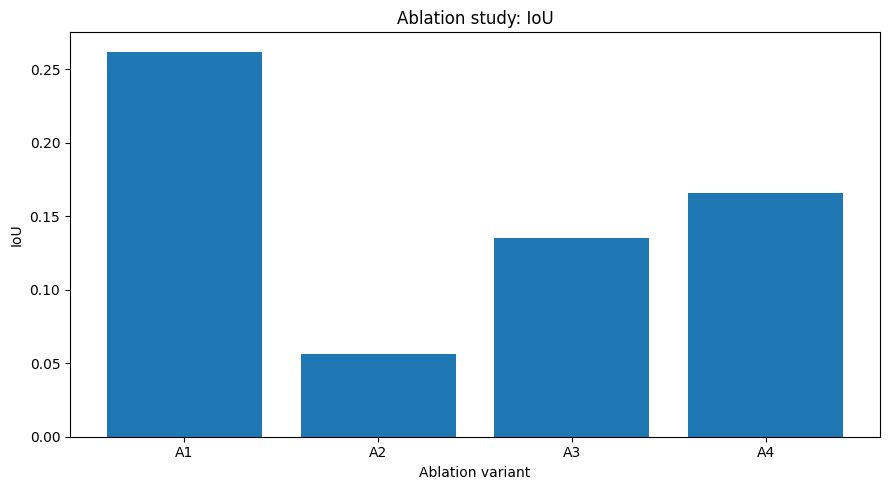

Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\taac_ablation_mcc.png


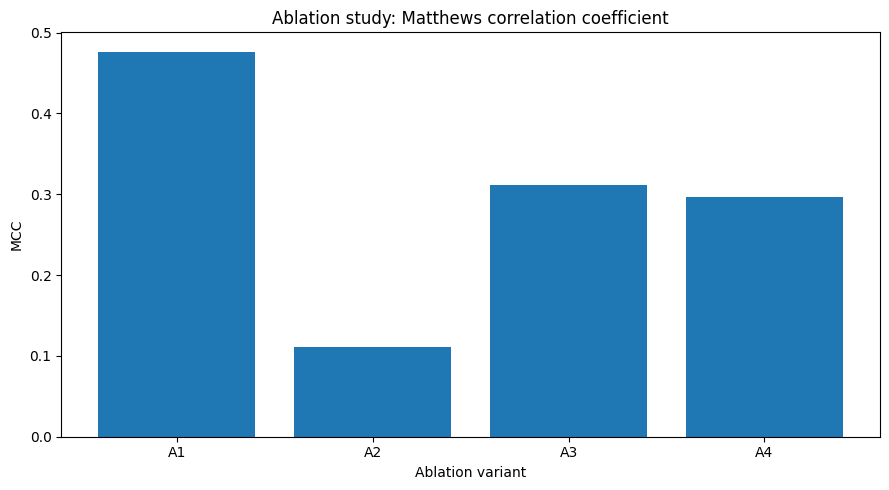

In [39]:

# ============================================================
# 17D. ABLATION STUDY FOR IMBALANCE-AWARE COMPONENTS
# ============================================================

def make_random_patches(X_arr, y_arr, n_patches, patch_size=PATCH_SIZE):
    """Random patch sampling without positive-patch balancing."""
    Xp, yp = [], []
    n, t, h, w, c = X_arr.shape

    for _ in tqdm(range(int(n_patches)), desc="Random patches"):
        idx = np.random.randint(0, n)
        top = np.random.randint(0, h - patch_size + 1)
        left = np.random.randint(0, w - patch_size + 1)
        x_patch, y_patch = crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)
        Xp.append(x_patch)
        yp.append(y_patch)

    Xp = np.asarray(Xp, dtype="float32")
    yp = np.asarray(yp, dtype="float32")
    return Xp, yp


def weighted_bce_dice_loss_no_fp(y_true, y_pred):
    """Ablation loss without false-positive penalty."""
    return 0.65 * weighted_bce_loss(y_true, y_pred) + 0.35 * dice_loss(y_true, y_pred)


def plain_bce_dice_loss_no_fp(y_true, y_pred):
    """Ablation loss without class weighting and without false-positive penalty."""
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.clip_by_value(tf.cast(y_pred, tf.float32), 1e-6, 1.0 - 1e-6)
    bce = tf.reduce_mean(keras.backend.binary_crossentropy(y_true, y_pred))
    return 0.65 * bce + 0.35 * dice_loss(y_true, y_pred)


def compile_model_with_custom_loss(model, loss_fn, lr=LEARNING_RATE):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=loss_fn,
        metrics=[dice_coef, iou_coef, precision_at_05, recall_at_05],
    )
    return model


def build_st_hrpnet_v1_no_skip(seq_len=SEQ_LEN, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    """Optional ablation architecture: ConvLSTM encoder-decoder without skip connections."""
    inputs = keras.Input(shape=(seq_len, None, None, n_channels), name="sequence_dynamic_no_skip")

    def td_conv_block(x, filters, name, dropout=0.0):
        x = layers.TimeDistributed(layers.Conv2D(filters, 3, padding="same"), name=f"{name}_td_conv1")(x)
        x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_td_bn1")(x)
        x = layers.TimeDistributed(layers.Activation("relu"), name=f"{name}_td_relu1")(x)
        x = layers.TimeDistributed(layers.Conv2D(filters, 3, padding="same"), name=f"{name}_td_conv2")(x)
        x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_td_bn2")(x)
        x = layers.TimeDistributed(layers.Activation("relu"), name=f"{name}_td_relu2")(x)
        if dropout and dropout > 0:
            x = layers.TimeDistributed(layers.Dropout(dropout), name=f"{name}_td_dropout")(x)
        return x

    x = td_conv_block(inputs, base, "noskip_enc1", dropout=0.03)
    x = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="noskip_pool1")(x)

    x = td_conv_block(x, base * 2, "noskip_enc2", dropout=0.05)
    x = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="noskip_pool2")(x)

    x = td_conv_block(x, base * 4, "noskip_enc3", dropout=0.08)
    x = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="noskip_pool3")(x)

    z = layers.ConvLSTM2D(base * 8, 3, padding="same", return_sequences=False, name="noskip_convlstm")(x)
    z = layers.BatchNormalization(name="noskip_bottleneck_bn")(z)
    z = layers.Activation("relu", name="noskip_bottleneck_relu")(z)

    u3 = layers.UpSampling2D((2, 2), name="noskip_up3")(z)
    d3 = conv_block_2d(u3, base * 4, "noskip_dec3", dropout=0.05)

    u2 = layers.UpSampling2D((2, 2), name="noskip_up2")(d3)
    d2 = conv_block_2d(u2, base * 2, "noskip_dec2", dropout=0.03)

    u1 = layers.UpSampling2D((2, 2), name="noskip_up1")(d2)
    d1 = conv_block_2d(u1, base, "noskip_dec1", dropout=0.02)

    outputs = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(d1)
    return keras.Model(inputs, outputs, name="ST_HRPNet_v1_NoSkip_Ablation")


def taac_load_or_train_model(model_name, model_builder, loss_fn, train_ds, val_ds, epochs):
    model = compile_model_with_custom_loss(model_builder(), loss_fn)
    model_dir = OUTPUT_DIR / model_name
    ckpt_path = model_dir / f"{model_name}_best.weights.h5"

    if TAAC_REUSE_EXISTING_ABLATION_WEIGHTS and ckpt_path.exists():
        print(f"Loading existing ablation weights: {ckpt_path}")
        model.load_weights(str(ckpt_path))
        hist_df = pd.DataFrame()
        return model, hist_df

    print(f"Training ablation model: {model_name}")
    model, hist_df, _ = train_model(
        model,
        train_ds,
        val_ds,
        name=model_name,
        epochs=int(epochs),
    )
    return model, hist_df


def taac_evaluate_model_variant(model_name, model_obj, input_type="sequence", threshold_mode="constrained", fixed_threshold=0.5):
    val_prob = taac_predict_cached(model_name, model_obj, X_val, input_type=input_type, split_name="validation", force=False)
    test_prob = taac_predict_cached(model_name, model_obj, X_test, input_type=input_type, split_name="test", force=False)

    if threshold_mode == "constrained":
        best_th, th_df = select_threshold_constrained(y_val, val_prob, model_name=model_name)
        th_df.to_csv(TAAC_OUTPUT_DIR / f"{taac_sanitize_name(model_name)}_threshold_search.csv", index=False)
        th = float(best_th)
    elif threshold_mode == "fixed":
        th = float(fixed_threshold)
    else:
        raise ValueError("threshold_mode must be 'constrained' or 'fixed'.")

    metrics = taac_evaluate_probability(
        y_true=y_test,
        y_prob=test_prob,
        threshold=th,
        model_name=model_name,
        note=threshold_mode,
    )

    if "measure_inference_time" in globals():
        inf_mean, inf_std = measure_inference_time(model_obj, input_type=input_type)
        metrics["inference_sec_per_sample_mean"] = inf_mean
        metrics["inference_sec_per_sample_std"] = inf_std

    return metrics


if RUN_TAAC_ABLATION:
    taac_require_vars([
        "X_train", "y_train", "X_val", "y_val", "X_test", "y_test",
        "X_train_patch", "y_train_patch", "X_val_patch", "y_val_patch",
        "make_dataset", "train_model", "build_st_hrpnet_v1_patchbalanced",
        "st_model"
    ])

    print("Preparing random-patch data for non-balanced ablation...")
    X_train_random_patch, y_train_random_patch = make_random_patches(X_train, y_train, N_TRAIN_PATCHES, PATCH_SIZE)
    X_val_random_patch, y_val_random_patch = make_random_patches(X_val, y_val, N_VAL_PATCHES, PATCH_SIZE)

    random_patch_summary_df = pd.DataFrame([
        {"split": "train_random_patch", "n": len(X_train_random_patch), "positive_pixel_ratio": float(y_train_random_patch.mean())},
        {"split": "val_random_patch", "n": len(X_val_random_patch), "positive_pixel_ratio": float(y_val_random_patch.mean())},
        {"split": "train_patch_balanced", "n": len(X_train_patch), "positive_pixel_ratio": float(y_train_patch.mean())},
        {"split": "val_patch_balanced", "n": len(X_val_patch), "positive_pixel_ratio": float(y_val_patch.mean())},
    ])
    taac_save_dataframe(random_patch_summary_df, "ablation_patch_sampling_summary.csv")

    train_random_ds = make_dataset(X_train_random_patch, y_train_random_patch, shuffle=True, augment=True)
    val_random_ds = make_dataset(X_val_random_patch, y_val_random_patch, shuffle=False, augment=False)

    ablation_rows = []

    # A. Architecture + random patches + loss without FP penalty.
    model_a, hist_a = taac_load_or_train_model(
        model_name="Ablation_A_RandomPatch_WBCE_Dice_NoFP",
        model_builder=build_st_hrpnet_v1_patchbalanced,
        loss_fn=weighted_bce_dice_loss_no_fp,
        train_ds=train_random_ds,
        val_ds=val_random_ds,
        epochs=TAAC_ABLATION_EPOCHS,
    )
    m_a = taac_evaluate_model_variant(
        "Ablation_A_RandomPatch_WBCE_Dice_NoFP",
        model_a,
        input_type="sequence",
        threshold_mode="fixed",
        fixed_threshold=0.5,
    )
    m_a["ablation_component"] = "random patches + WBCE-Dice loss + fixed threshold"
    ablation_rows.append(m_a)

    # B. Patch-balanced learning only, without FP-aware loss and without constrained thresholding.
    model_b, hist_b = taac_load_or_train_model(
        model_name="Ablation_B_PatchBalanced_WBCE_Dice_NoFP",
        model_builder=build_st_hrpnet_v1_patchbalanced,
        loss_fn=weighted_bce_dice_loss_no_fp,
        train_ds=train_patch_ds,
        val_ds=val_patch_ds,
        epochs=TAAC_ABLATION_EPOCHS,
    )
    m_b = taac_evaluate_model_variant(
        "Ablation_B_PatchBalanced_WBCE_Dice_NoFP",
        model_b,
        input_type="sequence",
        threshold_mode="fixed",
        fixed_threshold=0.5,
    )
    m_b["ablation_component"] = "patch-balanced + WBCE-Dice loss + fixed threshold"
    ablation_rows.append(m_b)

    # C. Patch-balanced + false-positive-aware loss, fixed threshold.
    m_c = taac_evaluate_model_variant(
        "Ablation_C_PatchBalanced_FPaware_Fixed05",
        st_model,
        input_type="sequence",
        threshold_mode="fixed",
        fixed_threshold=0.5,
    )
    m_c["ablation_component"] = "patch-balanced + FP-aware loss + fixed threshold"
    ablation_rows.append(m_c)

    # D. Full proposed framework: patch-balanced + FP-aware loss + constrained threshold.
    m_d = taac_evaluate_model_variant(
        "Ablation_D_FullFramework_ConstrainedThreshold",
        st_model,
        input_type="sequence",
        threshold_mode="constrained",
    )
    m_d["ablation_component"] = "patch-balanced + FP-aware loss + constrained threshold"
    ablation_rows.append(m_d)

    # Optional no-skip architecture.
    if RUN_TAAC_NOSKIP_ABLATION:
        model_ns, hist_ns = taac_load_or_train_model(
            model_name="Ablation_E_NoSkip_PatchBalanced_FPaware",
            model_builder=build_st_hrpnet_v1_no_skip,
            loss_fn=combined_hrp_loss,
            train_ds=train_patch_ds,
            val_ds=val_patch_ds,
            epochs=TAAC_ABLATION_EPOCHS,
        )
        m_ns = taac_evaluate_model_variant(
            "Ablation_E_NoSkip_PatchBalanced_FPaware",
            model_ns,
            input_type="sequence",
            threshold_mode="constrained",
        )
        m_ns["ablation_component"] = "no skip decoder + patch-balanced + FP-aware loss + constrained threshold"
        ablation_rows.append(m_ns)

    taac_ablation_df = pd.DataFrame(ablation_rows)

    ordered_cols = [
        "model", "ablation_component", "threshold_mode", "threshold",
        "iou", "dice_f1", "precision", "recall", "specificity", "fpr",
        "balanced_accuracy", "mcc", "pr_auc",
        "actual_positive_ratio", "predicted_positive_ratio",
        "tp", "fp", "fn", "tn"
    ]
    for c in ordered_cols:
        if c not in taac_ablation_df.columns:
            taac_ablation_df[c] = np.nan
    taac_ablation_df = taac_ablation_df[ordered_cols + [c for c in taac_ablation_df.columns if c not in ordered_cols]]
    taac_save_dataframe(taac_ablation_df, "taac_ablation_study_results.csv")

    # Bar chart for key metrics.
    plot_df = taac_ablation_df.copy()
    x_labels = [f"A{i+1}" for i in range(len(plot_df))]
    plot_df["short_label"] = x_labels

    plt.figure(figsize=(9, 5))
    plt.bar(plot_df["short_label"], plot_df["iou"])
    plt.xlabel("Ablation variant")
    plt.ylabel("IoU")
    plt.title("Ablation study: IoU")
    plt.xticks(rotation=0)
    plt.tight_layout()
    out_fig = TAAC_OUTPUT_DIR / "taac_ablation_iou.png"
    plt.savefig(out_fig, dpi=300, bbox_inches="tight")
    print("Saved:", out_fig)
    plt.show()

    plt.figure(figsize=(9, 5))
    plt.bar(plot_df["short_label"], plot_df["mcc"])
    plt.xlabel("Ablation variant")
    plt.ylabel("MCC")
    plt.title("Ablation study: Matthews correlation coefficient")
    plt.xticks(rotation=0)
    plt.tight_layout()
    out_fig = TAAC_OUTPUT_DIR / "taac_ablation_mcc.png"
    plt.savefig(out_fig, dpi=300, bbox_inches="tight")
    print("Saved:", out_fig)
    plt.show()

else:
    print("TAAC ablation study skipped.")


In [40]:

# ============================================================
# 17E. OPTIONAL INDEPENDENT PRECIPITATION VALIDATION
# ============================================================

def taac_parse_time_code(time_code):
    """Parse common JMA-like time codes. Returns pandas.Timestamp or None."""
    s = str(time_code)
    digits = re.sub(r"\D", "", s)
    for fmt in ["%Y%m%d%H%M", "%Y%m%d%H", "%Y%m%d"]:
        try:
            n = len(datetime.strptime("200001010000"[:len(digits)], fmt).strftime(fmt))
        except Exception:
            n = None
        try:
            if len(digits) == len(datetime.strptime(digits, fmt).strftime(fmt)):
                return pd.Timestamp(datetime.strptime(digits, fmt))
        except Exception:
            pass
    try:
        return pd.to_datetime(s)
    except Exception:
        return None


def taac_load_precip_masks_from_npy():
    if not PRECIP_MASK_NPY.exists():
        return None

    arr = np.load(PRECIP_MASK_NPY)
    arr = np.asarray(arr)

    if arr.ndim == 3:
        arr = arr[..., None]

    if arr.shape[0] != len(y_test):
        raise ValueError(f"Precip mask count mismatch: {arr.shape[0]} vs len(y_test)={len(y_test)}")

    if arr.shape[1:3] != y_test.shape[1:3]:
        resized = []
        for i in range(arr.shape[0]):
            resized_i = cv2.resize(arr[i, ..., 0].astype("float32"), (y_test.shape[2], y_test.shape[1]), interpolation=cv2.INTER_NEAREST)
            resized.append(resized_i[..., None])
        arr = np.asarray(resized, dtype="float32")

    arr = (arr > 0.5).astype("float32")
    return arr


def taac_load_precip_masks_from_png_dir():
    if not PRECIP_MASK_DIR.exists():
        return None

    masks = []
    missing = []

    for _, row in meta_test.iterrows():
        tc = str(row["target_time_code"])
        candidates = [
            PRECIP_MASK_DIR / f"{tc}.png",
            PRECIP_MASK_DIR / f"{tc}.jpg",
            PRECIP_MASK_DIR / f"{tc}.tif",
            PRECIP_MASK_DIR / f"{tc}.tiff",
        ]
        found = None
        for p in candidates:
            if p.exists():
                found = p
                break

        if found is None:
            missing.append(tc)
            masks.append(np.zeros_like(y_test[0], dtype="float32"))
            continue

        img = cv2.imread(str(found), cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise ValueError(f"Cannot read precipitation mask: {found}")

        img = cv2.resize(img, (y_test.shape[2], y_test.shape[1]), interpolation=cv2.INTER_NEAREST)
        masks.append((img > 0).astype("float32")[..., None])

    if missing:
        print("Missing precipitation mask files:", len(missing))
        print("First missing time codes:", missing[:5])

    return np.asarray(masks, dtype="float32")


def taac_load_precip_masks_from_grid_csv():
    if not PRECIP_GRID_CSV.exists():
        return None

    df = pd.read_csv(PRECIP_GRID_CSV)
    required = {"target_time_code", "lon", "lat", PRECIP_VALUE_COLUMN}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"precip_grid.csv missing columns: {missing}")

    h, w = y_test.shape[1], y_test.shape[2]
    masks = []

    for _, row_meta in meta_test.iterrows():
        tc = str(row_meta["target_time_code"])
        sub = df[df["target_time_code"].astype(str) == tc].copy()

        mask = np.zeros((h, w), dtype="float32")
        if not sub.empty:
            for _, r in sub.iterrows():
                try:
                    lon = float(r["lon"])
                    lat = float(r["lat"])
                    val = float(r[PRECIP_VALUE_COLUMN])
                except Exception:
                    continue

                if val < PRECIP_THRESHOLD:
                    continue

                x, ypix = lonlat_to_pixel(lon, lat, w, h, domain=INDONESIA_BBOX)
                if 0 <= x < w and 0 <= ypix < h:
                    mask[ypix, x] = 1.0

            # Light dilation to make sparse point/grid evidence spatially visible.
            kernel = np.ones((3, 3), np.uint8)
            mask = cv2.dilate(mask.astype(np.uint8), kernel, iterations=1).astype("float32")

        masks.append(mask[..., None])

    return np.asarray(masks, dtype="float32")


def taac_load_precip_masks_from_netcdf():
    if not PRECIP_NETCDF_DIR.exists():
        return None

    nc_files = sorted(PRECIP_NETCDF_DIR.glob("*.nc"))
    if not nc_files:
        return None

    try:
        import xarray as xr
    except Exception as e:
        print("xarray is not installed. NetCDF precipitation validation skipped.")
        print("Install if needed: pip install xarray netCDF4")
        return None

    print("Opening NetCDF precipitation files:", len(nc_files))
    ds = xr.open_mfdataset([str(p) for p in nc_files], combine="by_coords")

    var_candidates = [PRECIP_VALUE_COLUMN, "precipitation", "precipitationCal", "precipRate", "rain", "rain_rate"]
    precip_var = None
    for v in var_candidates:
        if v in ds.data_vars:
            precip_var = v
            break

    if precip_var is None:
        print("No recognized precipitation variable found. Available variables:", list(ds.data_vars))
        return None

    lat_name = "lat" if "lat" in ds.coords else ("latitude" if "latitude" in ds.coords else None)
    lon_name = "lon" if "lon" in ds.coords else ("longitude" if "longitude" in ds.coords else None)
    time_name = "time" if "time" in ds.coords else None

    if lat_name is None or lon_name is None:
        print("Latitude/longitude coordinates not found in NetCDF.")
        return None

    data = ds[precip_var]

    # Crop Indonesia region.
    lat_min, lat_max = INDONESIA_BBOX["lat_min"], INDONESIA_BBOX["lat_max"]
    lon_min, lon_max = INDONESIA_BBOX["lon_min"], INDONESIA_BBOX["lon_max"]

    lat_vals = ds[lat_name].values
    if lat_vals[0] < lat_vals[-1]:
        data = data.sel({lat_name: slice(lat_min, lat_max), lon_name: slice(lon_min, lon_max)})
    else:
        data = data.sel({lat_name: slice(lat_max, lat_min), lon_name: slice(lon_min, lon_max)})

    masks = []
    for _, row_meta in meta_test.iterrows():
        tc = row_meta["target_time_code"]
        ts = taac_parse_time_code(tc)

        if time_name is not None and ts is not None:
            try:
                arr = data.sel({time_name: ts.to_pydatetime()}, method="nearest").values
            except Exception:
                arr = data.isel({time_name: 0}).values
        else:
            arr = data.values
            if arr.ndim >= 3:
                arr = arr[0]

        arr = np.asarray(arr, dtype="float32")
        arr = np.nan_to_num(arr, nan=0.0)

        if arr.ndim > 2:
            arr = np.squeeze(arr)
            if arr.ndim > 2:
                arr = arr[0]

        mask = (arr >= float(PRECIP_THRESHOLD)).astype("float32")
        mask = cv2.resize(mask, (y_test.shape[2], y_test.shape[1]), interpolation=cv2.INTER_NEAREST)
        masks.append(mask[..., None])

    return np.asarray(masks, dtype="float32")


def taac_load_independent_precip_masks():
    loaders = [
        ("npy", taac_load_precip_masks_from_npy),
        ("png_dir", taac_load_precip_masks_from_png_dir),
        ("grid_csv", taac_load_precip_masks_from_grid_csv),
        ("netcdf", taac_load_precip_masks_from_netcdf),
    ]

    for name, loader in loaders:
        try:
            arr = loader()
            if arr is not None:
                print(f"Loaded independent precipitation masks from {name}: {arr.shape}")
                return arr, name
        except Exception as e:
            print(f"Failed loading precipitation masks from {name}: {repr(e)}")

    return None, None


def taac_create_precip_validation_templates():
    EXTERNAL_PRECIP_ROOT.mkdir(parents=True, exist_ok=True)
    PRECIP_MASK_DIR.mkdir(parents=True, exist_ok=True)
    PRECIP_NETCDF_DIR.mkdir(parents=True, exist_ok=True)

    template_times = pd.DataFrame({
        "target_time_code": meta_test["target_time_code"].astype(str).tolist(),
        "expected_mask_file": [f"masks_by_time/{tc}.png" for tc in meta_test["target_time_code"].astype(str).tolist()],
    })
    template_times_path = EXTERNAL_PRECIP_ROOT / "precip_validation_time_template.csv"
    template_times.to_csv(template_times_path, index=False)

    grid_template = pd.DataFrame({
        "target_time_code": [str(meta_test.iloc[0]["target_time_code"]) if len(meta_test) else ""],
        "lon": [106.8],
        "lat": [-6.2],
        PRECIP_VALUE_COLUMN: [12.0],
    })
    grid_template_path = EXTERNAL_PRECIP_ROOT / "precip_grid_template.csv"
    grid_template.to_csv(grid_template_path, index=False)

    readme_path = EXTERNAL_PRECIP_ROOT / "README_precip_validation.txt"
    readme_path.write_text(
        "Independent precipitation validation options:\n"
        "1. Save aligned binary masks as precip_test_masks_256.npy with shape (n_test, 256, 256, 1).\n"
        "2. Save binary mask images under masks_by_time/<target_time_code>.png.\n"
        "3. Save a grid CSV as precip_grid.csv with columns target_time_code, lon, lat, precip.\n"
        "4. Save GPM/GSMaP NetCDF files under netcdf/ and configure PRECIP_VALUE_COLUMN if needed.\n",
        encoding="utf-8"
    )

    print("Precipitation validation templates created:")
    print("-", template_times_path)
    print("-", grid_template_path)
    print("-", readme_path)


if RUN_TAAC_PRECIP_VALIDATION:
    taac_require_vars(["st_model", "X_test", "y_test", "meta_test"])

    precip_masks, precip_source = taac_load_independent_precip_masks()

    if precip_masks is None:
        print("Independent precipitation validation data not found.")
        print("This is expected unless GPM IMERG, GSMaP, radar, or rain-gauge-derived masks have been prepared.")
        taac_create_precip_validation_templates()
    else:
        st_threshold = taac_get_threshold_from_results("ST_HRPNet_v1_PatchBalanced", default=0.5)
        st_test_prob = taac_predict_cached(
            "ST_HRPNet_v1_PatchBalanced",
            st_model,
            X_test,
            input_type="sequence",
            split_name="test",
            force=False,
        )

        precip_metrics = binary_metrics_np(precip_masks, st_test_prob, threshold=st_threshold)
        precip_metrics["model"] = "ST_HRPNet_v1_PatchBalanced"
        precip_metrics["reference_source"] = precip_source
        precip_metrics["reference_threshold"] = PRECIP_THRESHOLD
        precip_metrics["csi"] = precip_metrics["iou"]
        precip_metrics["pod"] = precip_metrics["recall"]
        precip_metrics["far"] = precip_metrics["fp"] / (precip_metrics["tp"] + precip_metrics["fp"] + 1e-7)
        precip_metrics["pr_auc_against_precip"] = pr_auc_score_np(precip_masks, st_test_prob)

        precip_validation_df = pd.DataFrame([precip_metrics])
        taac_save_dataframe(precip_validation_df, "independent_precipitation_validation_summary.csv")

        # Per-sample summary.
        rows = []
        pred_mask = (st_test_prob >= st_threshold).astype("float32")
        for i in range(len(y_test)):
            m_i = binary_metrics_np(precip_masks[i], st_test_prob[i], threshold=st_threshold)
            rows.append({
                "sample_index": i,
                "target_time_code": meta_test.iloc[i]["target_time_code"],
                "hrp_label_positive_ratio": float(y_test[i].mean()),
                "precip_reference_positive_ratio": float(precip_masks[i].mean()),
                "predicted_positive_ratio": float(pred_mask[i].mean()),
                "iou_against_precip": m_i["iou"],
                "dice_f1_against_precip": m_i["dice_f1"],
                "pod_against_precip": m_i["recall"],
                "far_against_precip": m_i["fp"] / (m_i["tp"] + m_i["fp"] + 1e-7),
            })
        precip_validation_per_sample_df = pd.DataFrame(rows)
        taac_save_dataframe(precip_validation_per_sample_df, "independent_precipitation_validation_per_sample.csv")
else:
    print("Independent precipitation validation skipped.")


Independent precipitation validation data not found.
This is expected unless GPM IMERG, GSMaP, radar, or rain-gauge-derived masks have been prepared.
Precipitation validation templates created:
- external_precip_validation\precip_validation_time_template.csv
- external_precip_validation\precip_grid_template.csv
- external_precip_validation\README_precip_validation.txt


Missing precipitation mask files: 21
First missing time codes: ['2030', '2040', '2050', '2100', '2110']
Loaded independent precipitation masks from png_dir: (21, 256, 256, 1)
Selected event indices: [9, 7, 10, 6, 13]
Loaded cached prediction: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\ST_HRPNet_v1_PatchBalanced_validation_prob.npy (21, 256, 256, 1)
Loaded cached prediction: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\ST_HRPNet_v1_PatchBalanced_test_prob.npy (21, 256, 256, 1)
Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\event_case_09_2200.png


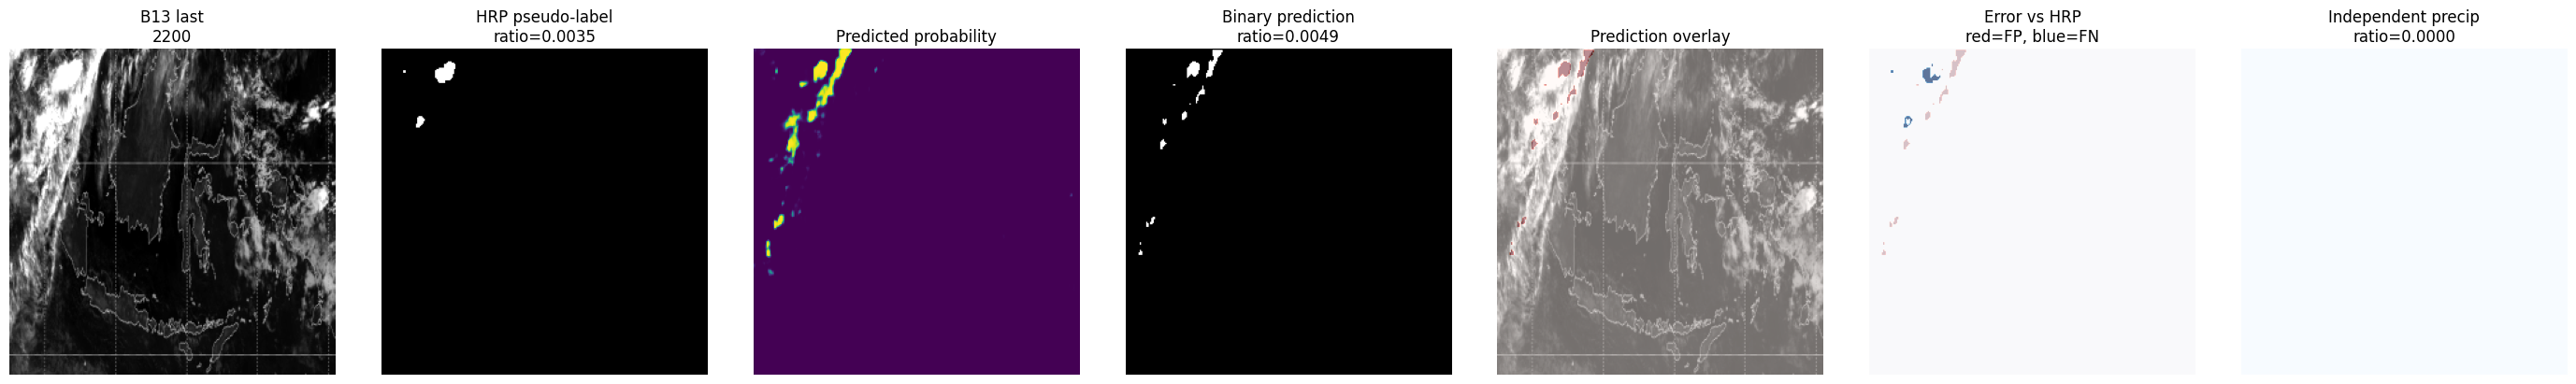

Loaded cached prediction: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\ST_HRPNet_v1_PatchBalanced_validation_prob.npy (21, 256, 256, 1)
Loaded cached prediction: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\ST_HRPNet_v1_PatchBalanced_test_prob.npy (21, 256, 256, 1)
Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\event_case_07_2140.png


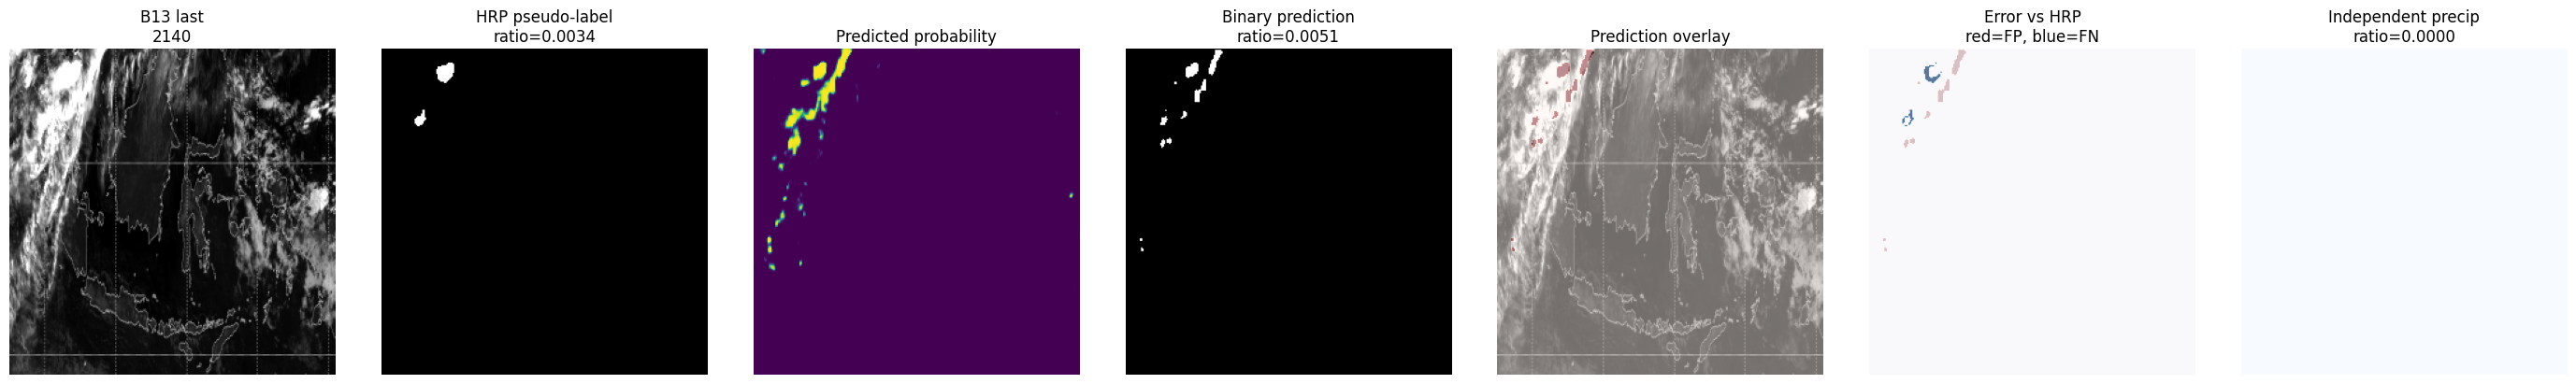

Loaded cached prediction: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\ST_HRPNet_v1_PatchBalanced_validation_prob.npy (21, 256, 256, 1)
Loaded cached prediction: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\ST_HRPNet_v1_PatchBalanced_test_prob.npy (21, 256, 256, 1)
Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\event_case_10_2210.png


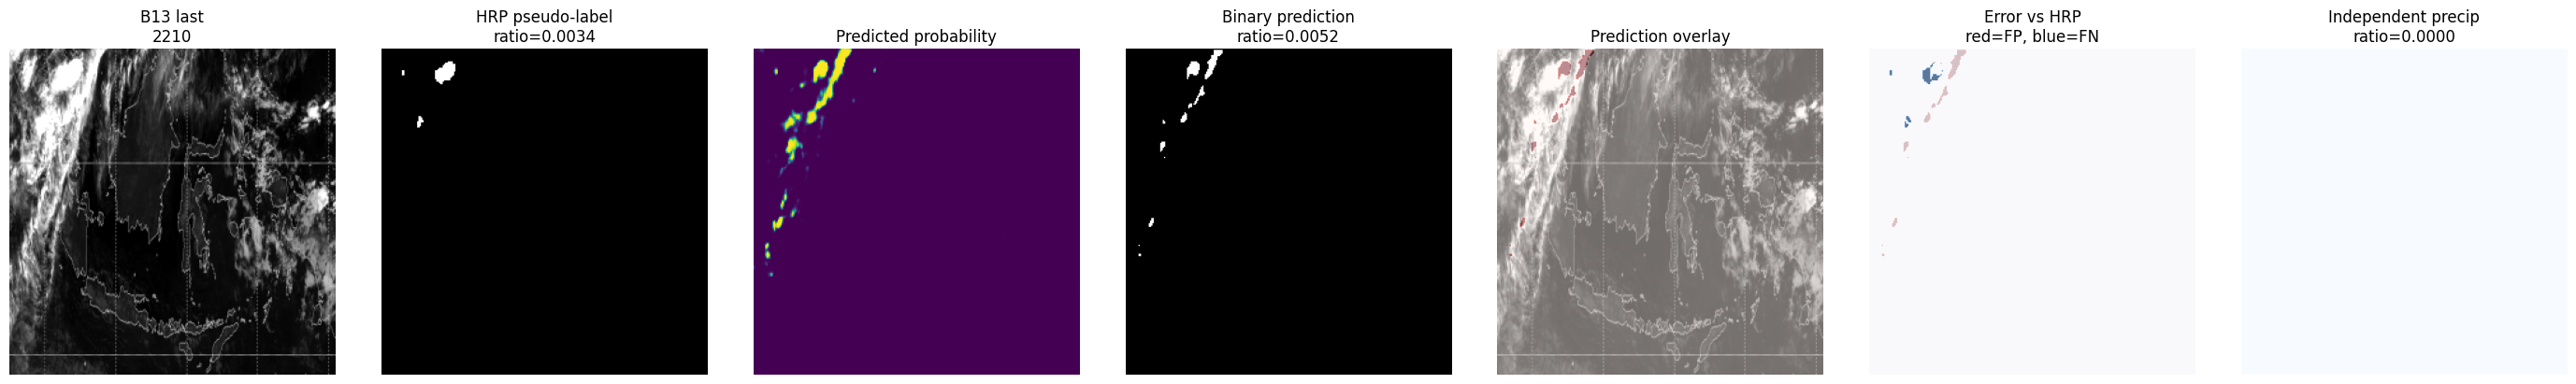

Loaded cached prediction: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\ST_HRPNet_v1_PatchBalanced_validation_prob.npy (21, 256, 256, 1)
Loaded cached prediction: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\ST_HRPNet_v1_PatchBalanced_test_prob.npy (21, 256, 256, 1)
Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\event_case_06_2130.png


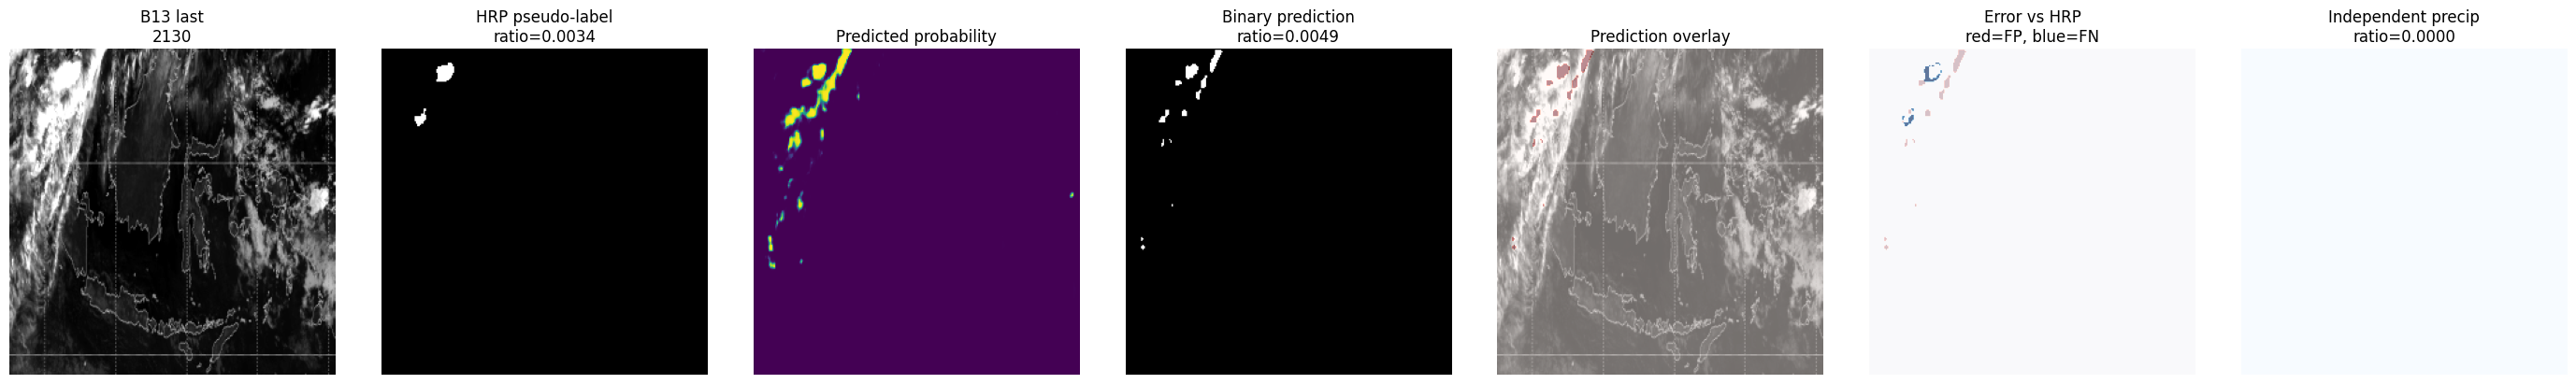

Loaded cached prediction: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\ST_HRPNet_v1_PatchBalanced_validation_prob.npy (21, 256, 256, 1)
Loaded cached prediction: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\ST_HRPNet_v1_PatchBalanced_test_prob.npy (21, 256, 256, 1)
Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\event_case_13_2240.png


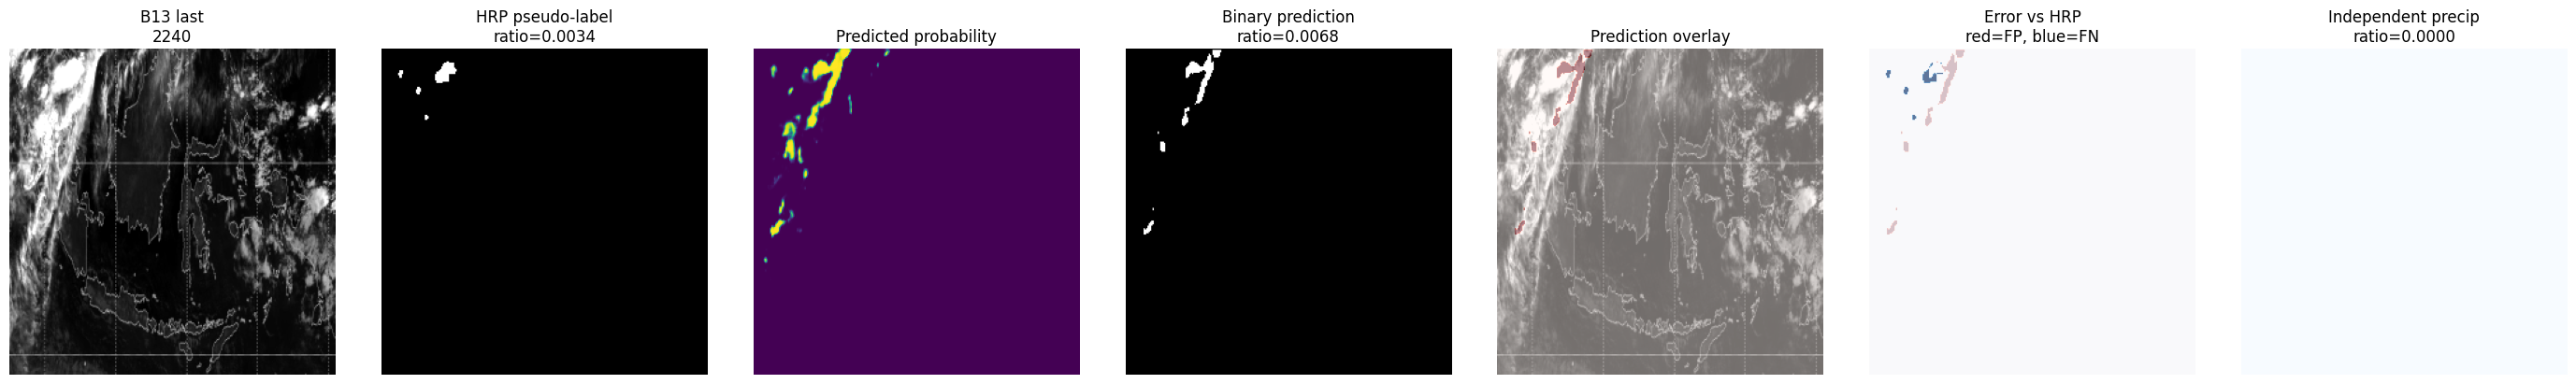

Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\event_based_case_summary.csv


,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,actual_positive_ratio,predicted_positive_ratio,tp,fp,fn,tn,sample_index,target_time_code
0,0.98,0.232143,0.376812,0.321981,0.454148,0.996647,0.003353,0.994751,0.725398,0.379847,0.003494,0.004929,104,219,125,65088,9,2200
1,0.98,0.251111,0.401421,0.335312,0.500000,0.996570,0.003430,0.994858,0.748285,0.406995,0.003448,0.005142,113,224,113,65086,7,2140
2,0.98,0.202991,0.337478,0.280236,0.424107,0.996264,0.003736,0.994308,0.710186,0.342011,0.003418,0.005173,95,244,129,65068,10,2210
3,0.98,0.272941,0.428835,0.364780,0.520179,0.996907,0.003093,0.995285,0.758543,0.433329,0.003403,0.004852,116,202,107,65111,6,2130
4,0.98,0.158261,0.273273,0.204494,0.411765,0.994580,0.005420,0.992615,0.703172,0.286851,0.003372,0.006790,91,354,130,64961,13,2240


WindowsPath('D:/RISETKOLABORASI/Artikel Siap Kirim/QUANTUM/Program/outputs/TAAC_extension_experiments/event_based_case_summary.csv')

In [41]:

# ============================================================
# 17F. EVENT-BASED METEOROLOGICAL CASE ANALYSIS
# ============================================================

def taac_select_event_indices(k=5):
    """Select cases with the largest HRP positive-pixel ratio in the test set."""
    ratios = np.asarray([float(y_test[i].mean()) for i in range(len(y_test))])
    order = np.argsort(-ratios)
    return order[:min(k, len(order))]


def taac_visualize_event_case(idx, threshold=None, precip_masks=None):
    idx = int(idx)
    if threshold is None:
        threshold = taac_get_threshold_from_results("ST_HRPNet_v1_PatchBalanced", default=0.5)

    st_test_prob = taac_predict_cached(
        "ST_HRPNet_v1_PatchBalanced",
        st_model,
        X_test,
        input_type="sequence",
        split_name="test",
        force=False,
    )

    prob = st_test_prob[idx, ..., 0]
    pred = (prob >= threshold).astype("float32")
    gt = y_test[idx, ..., 0].astype("float32")
    last_b13 = X_test[idx, -1, ..., INPUT_PRODUCTS.index("b13")]

    fp = ((pred == 1) & (gt == 0)).astype("float32")
    fn = ((pred == 0) & (gt == 1)).astype("float32")

    has_precip = precip_masks is not None and idx < len(precip_masks)
    ncols = 7 if has_precip else 6

    plt.figure(figsize=(4 * ncols, 4))

    plt.subplot(1, ncols, 1)
    plt.imshow(last_b13, cmap="gray")
    plt.title(f"B13 last\n{meta_test.iloc[idx]['target_time_code']}")
    plt.axis("off")

    plt.subplot(1, ncols, 2)
    plt.imshow(gt, cmap="gray")
    plt.title(f"HRP pseudo-label\nratio={gt.mean():.4f}")
    plt.axis("off")

    plt.subplot(1, ncols, 3)
    plt.imshow(prob, cmap="viridis")
    plt.title("Predicted probability")
    plt.axis("off")

    plt.subplot(1, ncols, 4)
    plt.imshow(pred, cmap="gray")
    plt.title(f"Binary prediction\nratio={pred.mean():.4f}")
    plt.axis("off")

    plt.subplot(1, ncols, 5)
    plt.imshow(last_b13, cmap="gray")
    plt.imshow(pred, cmap="Reds", alpha=0.45)
    plt.title("Prediction overlay")
    plt.axis("off")

    plt.subplot(1, ncols, 6)
    plt.imshow(fp, cmap="Reds", alpha=0.65)
    plt.imshow(fn, cmap="Blues", alpha=0.65)
    plt.title("Error vs HRP\nred=FP, blue=FN")
    plt.axis("off")

    if has_precip:
        precip = precip_masks[idx, ..., 0].astype("float32")
        plt.subplot(1, ncols, 7)
        plt.imshow(precip, cmap="Blues")
        plt.title(f"Independent precip\nratio={precip.mean():.4f}")
        plt.axis("off")

    plt.tight_layout()
    out_path = TAAC_OUTPUT_DIR / f"event_case_{idx:02d}_{meta_test.iloc[idx]['target_time_code']}.png"
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    print("Saved:", out_path)
    plt.show()

    case_metrics = binary_metrics_np(gt, prob, threshold=threshold)
    case_metrics["sample_index"] = idx
    case_metrics["target_time_code"] = meta_test.iloc[idx]["target_time_code"]
    return case_metrics


# Load precipitation masks if available.
try:
    _precip_masks_for_cases, _precip_source_for_cases = taac_load_independent_precip_masks()
except Exception:
    _precip_masks_for_cases, _precip_source_for_cases = None, None

event_indices = taac_select_event_indices(k=5)
event_rows = []

print("Selected event indices:", event_indices.tolist())

for idx in event_indices:
    row = taac_visualize_event_case(idx, precip_masks=_precip_masks_for_cases)
    event_rows.append(row)

event_case_summary_df = pd.DataFrame(event_rows)
taac_save_dataframe(event_case_summary_df, "event_based_case_summary.csv")


In [42]:

# ============================================================
# 17G. EXPORT MANUSCRIPT-READY SUMMARY FOR TAAC
# ============================================================

def taac_read_csv_if_exists(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    return pd.DataFrame()


main_results = taac_load_results_df_if_available()
ablation_results = taac_read_csv_if_exists(TAAC_OUTPUT_DIR / "taac_ablation_study_results.csv")
threshold_summary = taac_read_csv_if_exists(TAAC_OUTPUT_DIR / "threshold_sensitivity_summary_ST_HRPNet_v1.csv")
precip_summary = taac_read_csv_if_exists(TAAC_OUTPUT_DIR / "independent_precipitation_validation_summary.csv")
event_summary = taac_read_csv_if_exists(TAAC_OUTPUT_DIR / "event_based_case_summary.csv")

summary_md = []
summary_md.append(f"# TAAC extended experiment summary\n")
summary_md.append(f"Paper title: **{PAPER_TITLE_TAAC}**\n")
summary_md.append("## Existing model comparison\n")
if len(main_results) > 0:
    summary_md.append(main_results.to_markdown(index=False))
else:
    summary_md.append("Main model comparison CSV was not found. Run the original evaluation cell first.")

summary_md.append("\n## Ablation study\n")
if len(ablation_results) > 0:
    cols = [c for c in [
        "model", "ablation_component", "threshold_mode", "threshold",
        "iou", "dice_f1", "precision", "recall", "mcc", "pr_auc",
        "predicted_positive_ratio"
    ] if c in ablation_results.columns]
    summary_md.append(ablation_results[cols].to_markdown(index=False))
else:
    summary_md.append("Ablation results are not available. Run Cell 17D.")

summary_md.append("\n## Threshold sensitivity summary\n")
if len(threshold_summary) > 0:
    summary_md.append(threshold_summary.to_markdown(index=False))
else:
    summary_md.append("Threshold sensitivity summary is not available. Run Cell 17C.")

summary_md.append("\n## Independent precipitation validation\n")
if len(precip_summary) > 0:
    summary_md.append(precip_summary.to_markdown(index=False))
else:
    summary_md.append(
        "Independent precipitation validation has not been run because external GPM/GSMaP/radar/rain-gauge masks were not found. "
        "Use the templates in external_precip_validation/ to add independent precipitation evidence."
    )

summary_md.append("\n## Event-based case analysis\n")
if len(event_summary) > 0:
    cols = [c for c in [
        "sample_index", "target_time_code", "iou", "dice_f1",
        "precision", "recall", "mcc", "predicted_positive_ratio"
    ] if c in event_summary.columns]
    summary_md.append(event_summary[cols].to_markdown(index=False))
else:
    summary_md.append("Event-based case summary is not available. Run Cell 17F.")

summary_md.append("\n## Suggested manuscript integration\n")
summary_md.append(
    "- Add a new subsection titled **Ablation analysis of imbalance-aware components**.\n"
    "- Add a new subsection titled **Threshold sensitivity and positive-ratio stability**.\n"
    "- If independent precipitation masks are provided, add a subsection titled **Independent precipitation consistency assessment**.\n"
    "- Add 2-3 event-based qualitative examples to strengthen applied meteorological interpretation.\n"
)

summary_text = "\n".join(summary_md)
summary_path = TAAC_OUTPUT_DIR / "TAAC_extended_experiment_summary.md"
summary_path.write_text(summary_text, encoding="utf-8")

print("Saved manuscript-ready summary:", summary_path)
print(summary_text[:3000])


Saved manuscript-ready summary: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_extension_experiments\TAAC_extended_experiment_summary.md
# TAAC extended experiment summary

Paper title: **Himawari-derived heavy rainfall potential segmentation over Indonesia using an imbalance-aware spatiotemporal deep learning framework**

## Existing model comparison

Main model comparison CSV was not found. Run the original evaluation cell first.

## Ablation study

| model                                         | ablation_component                                     | threshold_mode   |   threshold |       iou |   dice_f1 |   precision |    recall |      mcc |   pr_auc |   predicted_positive_ratio |
|:----------------------------------------------|:-------------------------------------------------------|:-----------------|------------:|----------:|----------:|------------:|----------:|---------:|---------:|---------------------------:|
| Ablation_A_RandomPatch_WBCE_Dice_NoFP   


## Kriteria keputusan sebelum lanjut paper

Eksperimen V2 dapat dianggap **lebih layak untuk paper** jika:

1. `predicted_positive_ratio` tidak lagi mendekati 1.0.
2. `precision` naik signifikan dibanding eksperimen awal.
3. `specificity` dan `balanced_accuracy` tidak nol.
4. `MCC` bernilai positif.
5. ST-HRPNet v1 Patch-Balanced mengungguli baseline minimal pada IoU/Dice/PR-AUC atau menunjukkan trade-off terbaik antara recall dan false positive.
6. Visualisasi prediksi menunjukkan pola HRP yang masuk akal secara spasial, bukan seluruh citra menjadi positif.

Jika hasil masih rendah, jangan dipaksakan menjadi klaim "model terbaik". Framing paper dapat diarahkan sebagai **proof-of-concept with controlled threshold and imbalance-aware learning**, lalu dataset diperluas menjadi multi-hari untuk versi paper final.
